Deep Learning Prediction of Seasonal Groundwater Levels
## Four independent research experiments: post-monsoon 1994–2023 and three pre-monsoon periods

Each CSV is processed, split, trained, evaluated, and visualized independently.
No observations from one CSV are combined with another CSV for training or figures.

Models:
1. LSTM
2. GRU
3. CNN-LSTM
4. Hybrid LSTM-GRU

The supplied files contain monitoring-well location, observation date, and groundwater
depth/level. Therefore predictors are restricted to spatial coordinates, calendar variables,
and past groundwater observations. No rainfall/temperature/NDVI variables are invented.


In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import gc
import json
import random
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.patches as mpatches

import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import display, HTML

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

try:
    import tensorflow as tf
    from tensorflow.keras import Model, Input
    from tensorflow.keras.layers import Dense, LSTM, GRU, Conv1D, MaxPooling1D, Dropout
    from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
    from tensorflow.keras.optimizers import Adam
    print("TensorFlow:", tf.__version__)
    GPUS = tf.config.list_physical_devices("GPU")
    if GPUS:
        for gpu in GPUS:
            try:
                tf.config.experimental.set_memory_growth(gpu, True)
            except RuntimeError:
                pass
        print(f"GPU detected: {len(GPUS)} device(s)")
    else:
        print("WARNING: No GPU detected; training will use CPU.")
except ImportError:
    print("TensorFlow not installed in current environment; DL training requires TensorFlow/Colab environment.")

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
try:
    tf.random.set_seed(SEED)
except Exception:
    pass


TensorFlow: 2.21.0


In [2]:
DATASET_FILES = {
    "post_monsoon_1994_2023": "post-monsoon_wl_1994-2023.csv",
    "pre_monsoon_2014_2024": "pre-monsoon_2014-2024.csv",
    "pre_monsoon_2004_2013": "pre-monsoon_2004-2013.csv",
    "pre_monsoon_1994_2003": "pre-monsoon_1994-2003.csv",
}

LOOKBACK = 4
TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
EPOCHS = 40
BATCH_SIZE = 128
EARLY_STOPPING_PATIENCE = 8
LR_PATIENCE = 3

FEATURE_COLS = [
    "LATITUDE", "LONGITUDE",
    "year", "month", "day_of_year",
    "month_sin", "month_cos",
    "gw_lag_1", "gw_lag_2", "gw_lag_3",
    "gw_change_1", "gw_roll_mean_3", "gw_roll_std_3"
]

MODEL_COLORS = {
    "LSTM": "#e74c3c",           # RED
    "GRU": "#27ae60",            # GREEN
    "CNN-LSTM": "#00cec9",       # CYAN
    "Hybrid LSTM-GRU": "#0984e3",# BLUE
}
OBSERVED_COLOR = "#000000"       # BLACK

OUTPUT_ROOT = Path("outputs") / "HIGDSS_DL_4_SEPARATE_DATASETS"
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

def resolve_file(filename):
    exact_candidates = [
        Path.cwd() / filename,
        Path("/content") / filename,
        Path("/content/data") / filename,
        Path("/mnt/data") / filename,
    ]
    for p in exact_candidates:
        if p.is_file():
            return p
    stem = Path(filename).stem
    suffix = Path(filename).suffix
    for base in [Path.cwd(), Path("/content"), Path("/content/data"), Path("/mnt/data")]:
        matches = sorted(base.glob(stem + "*" + suffix))
        if matches:
            return matches[0]
    raise FileNotFoundError(
        f"Could not find '{filename}'. Upload the four CSV files to Colab "
        "or place them beside the notebook."
    )


In [3]:
def load_and_engineer_dataset(filename):
    path = resolve_file(filename)
    raw = pd.read_csv(path, low_memory=False)
    target_source = "WL_in_mbgl" if "WL_in_mbgl" in raw.columns else "DTWL"

    required = [
        "STATE_UT", "DISTRICT", "BLOCK", "VILLAGE",
        "LATITUDE", "LONGITUDE", "Date", target_source
    ]
    missing = [c for c in required if c not in raw.columns]
    if missing:
        raise ValueError(
            f"{filename} is missing required columns: {missing}\n"
            f"Available columns: {list(raw.columns)}"
        )

    df = raw[required].copy()
    df["date"] = pd.to_datetime(df["Date"], format="%d-%m-%y", errors="coerce")
    df = df.drop(columns=["Date"]).rename(columns={target_source: "groundwater_level"})

    for c in ["LATITUDE", "LONGITUDE", "groundwater_level"]:
        df[c] = pd.to_numeric(df[c], errors="coerce")

    df = df.dropna(
        subset=["date", "LATITUDE", "LONGITUDE", "groundwater_level"]
    ).copy()

    df["well_id"] = (
        df[["STATE_UT", "DISTRICT", "BLOCK", "VILLAGE", "LATITUDE", "LONGITUDE"]]
        .astype(str)
        .agg("|".join, axis=1)
    )

    df = df.sort_values(["well_id", "date"]).reset_index(drop=True)

    raw_rows = len(df)

    df = (
        df.groupby(["well_id", "date"], as_index=False)
        .agg({
            "STATE_UT": "first",
            "DISTRICT": "first",
            "BLOCK": "first",
            "VILLAGE": "first",
            "LATITUDE": "median",
            "LONGITUDE": "median",
            "groundwater_level": "mean",
        })
        .sort_values(["well_id", "date"])
        .reset_index(drop=True)
    )

    g = df.groupby("well_id", group_keys=False)
    df["gw_lag_1"] = g["groundwater_level"].shift(1)
    df["gw_lag_2"] = g["groundwater_level"].shift(2)
    df["gw_lag_3"] = g["groundwater_level"].shift(3)
    df["gw_change_1"] = (
        g["groundwater_level"].shift(1)
        - g["groundwater_level"].shift(2)
    )
    df["gw_roll_mean_3"] = g["groundwater_level"].transform(
        lambda s: s.shift(1).rolling(window=3, min_periods=1).mean()
    )
    df["gw_roll_std_3"] = g["groundwater_level"].transform(
        lambda s: s.shift(1).rolling(window=3, min_periods=2).std()
    )

    df["year"] = df["date"].dt.year
    df["month"] = df["date"].dt.month
    df["day_of_year"] = df["date"].dt.dayofyear
    df["month_sin"] = np.sin(2 * np.pi * df["month"] / 12.0)
    df["month_cos"] = np.cos(2 * np.pi * df["month"] / 12.0)

    df = df.dropna(subset=["gw_lag_1"]).copy()
    df["gw_lag_2"] = df["gw_lag_2"].fillna(df["gw_lag_1"])
    df["gw_lag_3"] = df["gw_lag_3"].fillna(df["gw_lag_2"])
    df["gw_change_1"] = df["gw_change_1"].fillna(0.0)
    df["gw_roll_std_3"] = df["gw_roll_std_3"].fillna(0.0)

    df = df.sort_values(["well_id", "date"]).reset_index(drop=True)

    info = {
        "source_file": Path(path).name,
        "usable_rows_after_cleaning": len(df),
        "unique_wells": int(df["well_id"].nunique()),
        "date_min": str(df["date"].min().date()),
        "date_max": str(df["date"].max().date()),
        "target_column": target_source,
    }
    return df, info


In [4]:
def chronological_split(df):
    unique_dates = np.sort(df["date"].dt.normalize().unique())
    train_cut = unique_dates[int(len(unique_dates) * TRAIN_RATIO)]
    test_cut = unique_dates[int(len(unique_dates) * (TRAIN_RATIO + VAL_RATIO))]

    train_df = df[df["date"].dt.normalize() < train_cut].copy()
    val_df = df[
        (df["date"].dt.normalize() >= train_cut)
        & (df["date"].dt.normalize() < test_cut)
    ].copy()
    test_df = df[df["date"].dt.normalize() >= test_cut].copy()

    if min(len(train_df), len(val_df), len(test_df)) == 0:
        raise ValueError("One chronological partition is empty.")

    return train_df, val_df, test_df, train_cut, test_cut


In [5]:
def prepare_sequences(df, train_df, val_df, test_df):
    scaler_x = MinMaxScaler()
    scaler_y = MinMaxScaler()

    scaler_x.fit(train_df[FEATURE_COLS])
    scaler_y.fit(train_df[["groundwater_level"]])

    all_x = scaler_x.transform(df[FEATURE_COLS]).astype(np.float32)
    all_y = scaler_y.transform(df[["groundwater_level"]]).ravel().astype(np.float32)

    train_start, train_end = train_df["date"].min(), train_df["date"].max()
    val_start, val_end = val_df["date"].min(), val_df["date"].max()
    test_start, test_end = test_df["date"].min(), test_df["date"].max()

    X_by_split = {"train": [], "val": [], "test": []}
    y_by_split = {"train": [], "val": [], "test": []}
    d_by_split = {"train": [], "val": [], "test": []}

    df_dates = df["date"].to_numpy()

    for _, idxs in df.groupby("well_id", sort=False).groups.items():
        idxs = np.asarray(list(idxs), dtype=np.int64)
        if len(idxs) <= LOOKBACK:
            continue

        for j in range(LOOKBACK, len(idxs)):
            target_idx = idxs[j]
            target_date = pd.Timestamp(df_dates[target_idx])

            if train_start <= target_date <= train_end:
                split = "train"
            elif val_start <= target_date <= val_end:
                split = "val"
            elif test_start <= target_date <= test_end:
                split = "test"
            else:
                continue

            history_indices = idxs[j - LOOKBACK:j]
            X_by_split[split].append(all_x[history_indices])
            y_by_split[split].append(all_y[target_idx])
            d_by_split[split].append(target_date)

    sequences = {}
    for split in ["train", "val", "test"]:
        X = np.asarray(X_by_split[split], dtype=np.float32)
        y = np.asarray(y_by_split[split], dtype=np.float32).reshape(-1, 1)
        dates = pd.to_datetime(d_by_split[split]).to_numpy()
        if len(X) == 0:
            raise ValueError(f"No sequences generated for {split}.")
        sequences[split] = {"X": X, "y": y, "dates": dates}

    return sequences, scaler_x, scaler_y


In [6]:
def build_lstm_model(input_shape):
    inputs = Input(shape=input_shape)
    x = LSTM(64, return_sequences=True)(inputs)
    x = Dropout(0.20)(x)
    x = LSTM(32)(x)
    x = Dropout(0.20)(x)
    x = Dense(16, activation="relu")(x)
    outputs = Dense(1)(x)
    model = Model(inputs, outputs, name="LSTM")
    model.compile(optimizer=Adam(0.002), loss="mse", metrics=["mae"])
    return model

def build_gru_model(input_shape):
    inputs = Input(shape=input_shape)
    x = GRU(64, return_sequences=True)(inputs)
    x = Dropout(0.20)(x)
    x = GRU(32)(x)
    x = Dropout(0.20)(x)
    x = Dense(16, activation="relu")(x)
    outputs = Dense(1)(x)
    model = Model(inputs, outputs, name="GRU")
    model.compile(optimizer=Adam(0.002), loss="mse", metrics=["mae"])
    return model

def build_cnn_lstm_model(input_shape):
    inputs = Input(shape=input_shape)
    x = Conv1D(64, 3, padding="same", activation="relu")(inputs)
    x = MaxPooling1D(2)(x)
    x = LSTM(48)(x)
    x = Dropout(0.20)(x)
    x = Dense(16, activation="relu")(x)
    outputs = Dense(1)(x)
    model = Model(inputs, outputs, name="CNN-LSTM")
    model.compile(optimizer=Adam(0.002), loss="mse", metrics=["mae"])
    return model

def build_hybrid_lstm_gru_model(input_shape):
    inputs = Input(shape=input_shape)
    x = LSTM(64, return_sequences=True)(inputs)
    x = Dropout(0.20)(x)
    x = GRU(32)(x)
    x = Dropout(0.20)(x)
    x = Dense(16, activation="relu")(x)
    outputs = Dense(1)(x)
    model = Model(inputs, outputs, name="Hybrid_LSTM_GRU")
    model.compile(optimizer=Adam(0.002), loss="mse", metrics=["mae"])
    return model

MODEL_BUILDERS = {
    "LSTM": build_lstm_model,
    "GRU": build_gru_model,
    "CNN-LSTM": build_cnn_lstm_model,
    "Hybrid LSTM-GRU": build_hybrid_lstm_gru_model,
}


In [7]:
def calculate_metrics(observed, predicted):
    observed = np.asarray(observed, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    error = predicted - observed

    mse = float(np.mean(error ** 2))
    rmse = float(np.sqrt(mse))
    mae = float(np.mean(np.abs(error)))
    r2 = float(r2_score(observed, predicted))

    if np.std(observed) > 0 and np.std(predicted) > 0:
        pearson_r = float(stats.pearsonr(observed, predicted)[0])
    else:
        pearson_r = np.nan

    nse_den = np.sum((observed - np.mean(observed)) ** 2)
    nse = float(1 - np.sum((observed - predicted) ** 2) / nse_den) if nse_den > 0 else np.nan

    alpha = np.std(predicted) / np.std(observed) if np.std(observed) > 0 else np.nan
    beta = np.mean(predicted) / np.mean(observed) if np.mean(observed) != 0 else np.nan
    kge = (
        float(1 - np.sqrt(
            (pearson_r - 1) ** 2 + (alpha - 1) ** 2 + (beta - 1) ** 2
        ))
        if np.isfinite(pearson_r) else np.nan
    )

    willmott_den = np.sum(
        (np.abs(predicted - np.mean(observed)) +
         np.abs(observed - np.mean(observed))) ** 2
    )
    willmott_d = (
        float(1 - np.sum((predicted - observed) ** 2) / willmott_den)
        if willmott_den > 0 else np.nan
    )

    lmi_den = np.sum(np.abs(observed - np.mean(observed)))
    lmi = (
        float(1 - np.sum(np.abs(predicted - observed)) / lmi_den)
        if lmi_den > 0 else np.nan
    )

    nrmse = (
        float(rmse / np.mean(np.abs(observed)))
        if np.mean(np.abs(observed)) > 0 else np.nan
    )

    mape = float(
        np.mean(np.abs(error) / np.maximum(np.abs(observed), 1e-6)) * 100
    )

    return {
        "RMSE": rmse, "MAE": mae, "R2": r2, "Pearson_r": pearson_r,
        "KGE": kge, "NSE": nse, "NRMSE": nrmse, "Willmott_d": willmott_d,
        "LMI": lmi, "MSE": mse, "MAPE_%": mape,
    }

def make_metric_table(predictions, observed):
    rows = []
    for model_name, pred in predictions.items():
        row = {"Model": model_name}
        row.update(calculate_metrics(observed, pred))
        rows.append(row)
    return pd.DataFrame(rows)


In [8]:


import os
import json
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as ticker
import plotly.graph_objects as go
from plotly.subplots import make_subplots

warnings.filterwarnings("ignore")

SHOW_FIGURES = True  # Display both static PNG and interactive Plotly figures directly in notebook

# Styling constants matching reference figures
PLOT_FACE = "#ffffff"      # Warm cream / parchment background matching Figure 5
GRID_COLOR = "#d5d8dc"     # Crisp subtle gridlines
BORDER_COLOR = "#000000"   # Deep solid black spines

MODEL_COLORS = {
    "LSTM": "#e74c3c",           # RED
    "GRU": "#27ae60",            # GREEN
    "CNN-LSTM": "#00cec9",       # CYAN
    "Hybrid LSTM-GRU": "#0984e3",# BLUE
}
OBSERVED_COLOR = "#000000"       # BLACK

OBSERVED_STYLE = {"linestyle": "-", "color": "#000000", "linewidth": 1.6}
MODEL_STYLES = {
    "LSTM": {"linestyle": "-", "color": "#e74c3c", "linewidth": 1.3},
    "GRU": {"linestyle": "-", "color": "#27ae60", "linewidth": 1.3},
    "CNN-LSTM": {"linestyle": "-", "color": "#00cec9", "linewidth": 1.3},
    "Hybrid LSTM-GRU": {"linestyle": "-", "color": "#0984e3", "linewidth": 1.3},
}

DATASET_FILES = {
    "post_monsoon_1994_2023": "post-monsoon_wl_1994-2023.csv",
    "pre_monsoon_2014_2024": "pre-monsoon_2014-2024.csv",
    "pre_monsoon_2004_2013": "pre-monsoon_2004-2013.csv",
    "pre_monsoon_1994_2003": "pre-monsoon_1994-2003.csv",
}

DATASET_TITLES = {
    "post_monsoon_1994_2023": "Post-Monsoon Season (1994–2023)",
    "pre_monsoon_2014_2024": "Pre-Monsoon Season (2014–2024)",
    "pre_monsoon_2004_2013": "Pre-Monsoon Season (2004–2013)",
    "pre_monsoon_1994_2003": "Pre-Monsoon Season (1994–2003)",
}

OUTPUT_ROOT = Path("outputs") / "HIGDSS_DL_4_SEPARATE_DATASETS"

FEATURE_COLS = [
    "LATITUDE", "LONGITUDE",
    "year", "month", "day_of_year",
    "month_sin", "month_cos",
    "gw_lag_1", "gw_lag_2", "gw_lag_3",
    "gw_change_1", "gw_roll_mean_3", "gw_roll_std_3"
]

def style_axis(ax, facecolor=PLOT_FACE):
    ax.set_facecolor(facecolor)
    ax.grid(True, color=GRID_COLOR, linestyle="-", linewidth=0.8, alpha=0.7)
    for spine in ax.spines.values():
        spine.set_color(BORDER_COLOR)
        spine.set_linewidth(1.8)
    ax.tick_params(direction="out", width=1.3, length=5, colors=BORDER_COLOR)

def is_notebook():
    try:
        from IPython import get_ipython
        if get_ipython() is not None:
            return True
    except Exception:
        pass
    return False

def save_and_show_figure(fig, path, dpi=600):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, dpi=dpi, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    if SHOW_FIGURES and is_notebook():
        try:
            from IPython.display import display, Image
            display(Image(filename=str(path)))
        except Exception:
            pass

def save_and_show_plotly(fig, path, width=1200, height=520):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    stem = path.stem
    while stem.endswith("_interactive"):
        stem = stem[:-len("_interactive")]
    html_path = path.parent / f"{stem}_interactive.html"
    fig.write_html(str(html_path), include_plotlyjs="cdn")
    if SHOW_FIGURES and is_notebook():
        try:
            from IPython.display import display
            display(fig)
        except Exception:
            try:
                from IPython.display import display, HTML
                display(HTML(fig.to_html(include_plotlyjs="cdn", full_html=False)))
            except Exception:
                try:
                    fig.show()
                except Exception:
                    pass

# ------------------------------------------------------------------------------
# 00. REGIONAL OBSERVED GROUNDWATER TIMELINE (REAL OBSERVED DATA ONLY)
# ------------------------------------------------------------------------------
def plot_observed_timeline(raw_df, out_path, dataset_title):
    date_col = "date" if "date" in raw_df.columns else ("Date" if "Date" in raw_df.columns else None)
    gw_col = "groundwater_level" if "groundwater_level" in raw_df.columns else ("DTWL" if "DTWL" in raw_df.columns else "WL_in_mbgl")
    if date_col is None or gw_col not in raw_df.columns:
        return

    df = raw_df.copy()
    df["Date"] = pd.to_datetime(df[date_col], errors="coerce")
    df = df.dropna(subset=["Date", gw_col])

    # Real data grouped by Date (regional mean and real IQR)
    daily = df.groupby("Date")[gw_col].agg(
        Observed="mean",
        Q25=lambda x: x.quantile(0.25),
        Q75=lambda x: x.quantile(0.75),
    ).reset_index().sort_values("Date")
    if len(daily) == 0:
        return

    fig, ax = plt.subplots(figsize=(10.5, 4.6), dpi=600)
    fig.patch.set_facecolor("white")
    ax.set_facecolor("white")

    for spine in ax.spines.values():
        spine.set_color("#777777")
        spine.set_linewidth(0.9)
    ax.grid(False)

    ax.fill_between(
        daily["Date"], daily["Q25"], daily["Q75"],
        color="#cbd5e1", alpha=0.35, label="Interquartile Range (25th–75th %)", zorder=3
    )
    ax.plot(daily["Date"], daily["Observed"], color="#000000", linewidth=1.5, label="Observed Regional Mean", zorder=8)

    ax.set_title(f"Regional Observed Groundwater Timeline — {dataset_title}", fontweight="bold", fontsize=11.5, pad=10)
    ax.set_xlabel("Time (Years)", fontweight="bold", fontsize=9.5)
    ax.set_ylabel("Groundwater Level (m bgl)", fontweight="bold", fontsize=9.5)

    year_span = (daily["Date"].max() - daily["Date"].min()).days / 365.25
    ax.xaxis.set_major_locator(mdates.YearLocator(2 if year_span > 10 else 1))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.legend(loc="upper right", fontsize=8.0, frameon=True, facecolor="white", edgecolor="#777777", framealpha=0.95)

    fig.tight_layout()
    save_and_show_figure(fig, out_path, dpi=600)

    # Interactive version
    fig_i = go.Figure()
    fig_i.add_trace(go.Scatter(
        x=daily["Date"], y=daily["Q75"], mode="lines", line=dict(width=0), showlegend=False, hoverinfo="skip"
    ))
    fig_i.add_trace(go.Scatter(
        x=daily["Date"], y=daily["Q25"], mode="lines", fill="tonexty", fillcolor="rgba(203, 213, 225, 0.4)",
        line=dict(width=0), name="IQR (25th–75th %)", hoverinfo="skip"
    ))
    fig_i.add_trace(go.Scatter(
        x=daily["Date"], y=daily["Observed"], mode="lines", name="Observed Regional Mean",
        line=dict(color="#000000", width=2.0),
        hovertemplate="<b>Date:</b> %{x|%b %Y}<br><b>GW Level:</b> %{y:.2f} mbgl<extra></extra>"
    ))
    fig_i.update_layout(
        title=dict(text=f"<b>Regional Observed Groundwater Timeline — {dataset_title}</b>", font=dict(size=14, family="Arial")),
        xaxis=dict(title="<b>Time (Years)</b>", showgrid=False, linecolor="#777777", linewidth=0.9, mirror=True),
        yaxis=dict(title="<b>Groundwater Level (m bgl)</b>", showgrid=False, linecolor="#777777", linewidth=0.9, mirror=True),
        plot_bgcolor="white", paper_bgcolor="white",
        width=1200, height=520,
        margin=dict(l=65, r=40, t=80, b=60),
        legend=dict(orientation="h", yanchor="bottom", y=1.02, xanchor="right", x=1, bgcolor="rgba(255,255,255,0.95)", bordercolor="#777777", borderwidth=0.8),
    )
    save_and_show_plotly(fig_i, out_path.with_name(out_path.stem + "_interactive"), width=1200, height=520)

# ------------------------------------------------------------------------------
# 02. TIME SERIES PLOT (MATCHING USER REFERENCE IMAGE EXACTLY)
# ------------------------------------------------------------------------------
def plot_time_series_publication(pred_df, split_date, out_path, dataset_title):
    models = [m for m in ["LSTM", "GRU", "CNN-LSTM", "Hybrid LSTM-GRU"] if m in pred_df.columns]
    df = pred_df.copy()
    df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
    df = df.dropna(subset=["Date"]).sort_values("Date")

    # Real data grouped by Date (regional mean only for visualization)
    daily = df.groupby("Date")[["Observed"] + models].mean().reset_index().sort_values("Date")
    if len(daily) == 0:
        return

    # Common standardization across all series
    all_vals = np.concatenate([daily[col].dropna().values for col in ["Observed"] + models])
    common_mean = float(np.mean(all_vals))
    common_std = float(np.std(all_vals))
    if common_std == 0 or np.isnan(common_std):
        common_std = 1.0

    daily_scaled = pd.DataFrame({"Date": daily["Date"]})
    daily_scaled["Observed"] = (daily["Observed"] - common_mean) / common_std
    for m in models:
        daily_scaled[m] = (daily[m] - common_mean) / common_std

    fig, ax = plt.subplots(figsize=(10.5, 4.6), dpi=600)
    fig.patch.set_facecolor("white")
    ax.set_facecolor("white")

    # Thin gray frame
    for spine in ax.spines.values():
        spine.set_color("#777777")
        spine.set_linewidth(0.9)

    ax.grid(False)

    # Horizontal black dashed zero reference line
    ax.axhline(0, color="black", linestyle="--", linewidth=1.0, zorder=3)

    # Train/Test boundary
    if split_date is not None:
        split_ts = pd.Timestamp(split_date)
        date_span_days = max(1, (daily["Date"].max() - daily["Date"].min()).days)
        half_width = max(pd.Timedelta(days=15), pd.Timedelta(days=int(date_span_days * 0.012)))
        split_start = split_ts - half_width
        split_end = split_ts + half_width

        ax.axvspan(split_start, split_end, color="#f28e8e", alpha=0.55, zorder=2, label="Train/Test Split")
        ax.axvline(split_ts, color="black", linestyle="--", linewidth=1.0, zorder=4)

    # Model curves: LSTM (Red), GRU (Green), CNN-LSTM (Cyan), Hybrid LSTM-GRU (Blue)
    model_color_map = {
        "LSTM": "#e74c3c",           # RED
        "GRU": "#27ae60",            # GREEN
        "CNN-LSTM": "#00cec9",       # CYAN
        "Hybrid LSTM-GRU": "#0984e3",# BLUE
    }

    for m in models:
        ax.plot(
            daily_scaled["Date"], daily_scaled[m],
            color=model_color_map.get(m, "#e67e22"),
            linewidth=1.3, label=m, zorder=6
        )

    # Black observed line on top
    ax.plot(
        daily_scaled["Date"], daily_scaled["Observed"],
        color="#000000", linewidth=1.6, label="Observed", zorder=8
    )

    ax.set_xlabel("Time (Years)", fontsize=9.5, fontweight="bold", color="#222222")
    ax.set_ylabel("Standardized Groundwater Level", fontsize=9.5, fontweight="bold", color="#222222")

    year_span = (daily["Date"].max() - daily["Date"].min()).days / 365.25
    ax.xaxis.set_major_locator(mdates.YearLocator(2 if year_span > 10 else 1))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.xaxis.set_minor_locator(mdates.YearLocator(1))

    y_min = float(daily_scaled[["Observed"] + models].min().min())
    y_max = float(daily_scaled[["Observed"] + models].max().max())
    y_pad = max(0.2, (y_max - y_min) * 0.08)
    ax.set_ylim(y_min - y_pad, y_max + y_pad)

    ax.tick_params(direction="out", length=4, width=0.8, colors="#333333", labelsize=8.5)

    ax.legend(
        loc="upper right", frameon=True, facecolor="white",
        edgecolor="#777777", framealpha=0.95, fontsize=8.0, ncol=max(2, len(models) + 1)
    )

    fig.tight_layout()
    save_and_show_figure(fig, out_path, dpi=600)

def plot_time_series_interactive(pred_df, split_date, out_path, dataset_title):
    models = [m for m in ["LSTM", "GRU", "CNN-LSTM", "Hybrid LSTM-GRU"] if m in pred_df.columns]
    df = pred_df.copy()
    df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
    df = df.dropna(subset=["Date"]).sort_values("Date")

    daily = df.groupby("Date")[["Observed"] + models].mean().reset_index().sort_values("Date")
    if len(daily) == 0:
        return

    all_vals = np.concatenate([daily[col].dropna().values for col in ["Observed"] + models])
    common_mean = float(np.mean(all_vals))
    common_std = float(np.std(all_vals))
    if common_std == 0 or np.isnan(common_std):
        common_std = 1.0

    daily_scaled = pd.DataFrame({"Date": daily["Date"]})
    daily_scaled["Observed"] = (daily["Observed"] - common_mean) / common_std
    for m in models:
        daily_scaled[m] = (daily[m] - common_mean) / common_std

    fig = go.Figure()

    fig.add_hline(y=0.0, line_dash="dash", line_color="black", line_width=1.0)

    if split_date is not None:
        split_ts = pd.Timestamp(split_date)
        date_span_days = max(1, (daily["Date"].max() - daily["Date"].min()).days)
        half_width = max(pd.Timedelta(days=15), pd.Timedelta(days=int(date_span_days * 0.012)))
        split_start = split_ts - half_width
        split_end = split_ts + half_width

        fig.add_vrect(
            x0=str(split_start.date()), x1=str(split_end.date()),
            fillcolor="rgba(242, 142, 142, 0.55)", line_width=0,
            annotation_text="Train/Test Split", annotation_position="top left",
            annotation_font=dict(size=10, color="#d63031")
        )
        fig.add_vline(x=str(split_ts.date()), line_dash="dash", line_color="black", line_width=1.0)

    model_color_map = {
        "LSTM": "#e74c3c",           # RED
        "GRU": "#27ae60",            # GREEN
        "CNN-LSTM": "#00cec9",       # CYAN
        "Hybrid LSTM-GRU": "#0984e3",# BLUE
    }

    for m in models:
        fig.add_trace(go.Scatter(
            x=daily_scaled["Date"], y=daily_scaled[m], mode="lines", name=m,
            line=dict(color=model_color_map.get(m, "#e67e22"), width=1.5),
            customdata=daily[m].values,
            hovertemplate=f"<b>{m}</b><br>Standardized: %{{y:.3f}}<br>Physical Level: %{{customdata:.2f}} mbgl<extra></extra>"
        ))

    fig.add_trace(go.Scatter(
        x=daily_scaled["Date"], y=daily_scaled["Observed"], mode="lines", name="Observed",
        line=dict(color="#000000", width=2.0),
        customdata=daily["Observed"].values,
        hovertemplate="<b>Observed</b><br>Standardized: %{y:.3f}<br>Physical Level: %{customdata:.2f} mbgl<extra></extra>"
    ))

    fig.update_layout(
        title=dict(
            text=f"<b>Time Series: Observed vs Deep Learning Predictions — {dataset_title}</b>",
            font=dict(size=14, family="Arial", color="#111111"),
            x=0.5, xanchor="center"
        ),
        xaxis=dict(
            title="<b>Time (Years)</b>",
            showgrid=False,
            linecolor="#777777", linewidth=0.9, mirror=True,
            tickfont=dict(size=10),
            rangeselector=dict(
                buttons=[
                    dict(count=5, label="5Y", step="year", stepmode="backward"),
                    dict(count=10, label="10Y", step="year", stepmode="backward"),
                    dict(step="all", label="ALL"),
                ],
                bgcolor="rgba(255,255,255,0.9)",
                bordercolor="#777777",
                borderwidth=0.8,
            ),
            rangeslider=dict(visible=True, thickness=0.08),
            type="date"
        ),
        yaxis=dict(
            title="<b>Standardized Groundwater Level</b>",
            showgrid=False,
            linecolor="#777777", linewidth=0.9, mirror=True,
            tickfont=dict(size=10),
        ),
        plot_bgcolor="white", paper_bgcolor="white",
        width=1200, height=520,
        legend=dict(
            orientation="h", yanchor="bottom", y=1.02, xanchor="right", x=1.0,
            bgcolor="rgba(255,255,255,0.95)", bordercolor="#777777", borderwidth=0.8, font=dict(size=10)
        ),
        margin=dict(l=65, r=40, t=80, b=60),
        hovermode="x unified",
    )
    save_and_show_plotly(fig, out_path, width=1200, height=520)

# ------------------------------------------------------------------------------
# 03. CORRELATION MATRIX (PUBLICATION + EXPANDED INTERACTIVE)
# ------------------------------------------------------------------------------
def plot_correlation_matrix_publication(corr, out_path, dataset_title):
    if isinstance(corr, pd.DataFrame):
        if not (corr.index.equals(corr.columns)):
            numeric_df = corr.select_dtypes(include=[np.number])
            cols = [c for c in numeric_df.columns if c not in ["well_id", "date", "Date"]]
            corr = numeric_df[cols].corr()
    valid_cols = [c for c in corr.columns if not corr[c].isna().all()]
    corr = corr.loc[valid_cols, valid_cols]
    cols = list(corr.columns)
    data = corr.values
    n = len(cols)
    
    fig, ax = plt.subplots(figsize=(max(11, n * 0.78), max(9.5, n * 0.68)), dpi=300)
    im = ax.imshow(data, cmap="coolwarm", vmin=-1.0, vmax=1.0, aspect="auto")
    ax.set_xticks(np.arange(n))
    ax.set_yticks(np.arange(n))
    ax.set_xticklabels(cols, rotation=90, ha="center", fontsize=9.0, fontweight="bold")
    ax.set_yticklabels(cols, fontsize=9.0, fontweight="bold")
    
    ax.set_xticks(np.arange(n + 1) - 0.5, minor=True)
    ax.set_yticks(np.arange(n + 1) - 0.5, minor=True)
    ax.grid(which="minor", color="white", linestyle="-", linewidth=1.4)
    ax.tick_params(which="minor", bottom=False, left=False)
    
    for i in range(n):
        for j in range(n):
            val = data[i, j]
            text_color = "white" if abs(val) > 0.45 else "black"
            ax.text(
                j, i, f"{val:.2f}", ha="center", va="center", fontsize=8.0,
                color=text_color, fontweight="normal" if abs(val) < 0.70 else "bold"
            )
            
    cbar = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.03)
    cbar.set_ticks(np.linspace(-1, 1, 9))
    cbar.set_label("Pearson Correlation Coefficient", fontweight="bold", fontsize=10.5)
    cbar.outline.set_edgecolor("black")
    cbar.outline.set_linewidth(1.2)
    
    ax.set_title(f"Correlation Matrix — {dataset_title}", fontweight="bold", fontsize=13.5, pad=14)
    fig.patch.set_linewidth(2.0)
    fig.patch.set_edgecolor("black")
    fig.tight_layout()
    save_and_show_figure(fig, out_path, dpi=300)

def plot_correlation_matrix_interactive(corr, out_path, dataset_title):
    valid_cols = [c for c in corr.columns if not corr[c].isna().all()]
    corr = corr.loc[valid_cols, valid_cols]
    cols = list(corr.columns)
    z = np.round(corr.values, 2)
    fig = go.Figure(data=go.Heatmap(
        z=z, x=cols, y=cols,
        colorscale="RdBu_r", zmin=-1.0, zmax=1.0,
        text=z, texttemplate="%{text:.2f}", textfont={"size": 11},
        colorbar=dict(title=dict(text="Correlation", font=dict(family="Arial", size=12, color="black"))),
        hovertemplate="<b>Feature X:</b> %{x}<br><b>Feature Y:</b> %{y}<br><b>Correlation:</b> %{z:.3f}<extra></extra>"
    ))
    fig.update_layout(
        title=dict(text=f"<b>Interactive Correlation Matrix — {dataset_title}</b>", font=dict(size=16, family="Arial Black")),
        xaxis=dict(tickangle=-90, tickfont=dict(size=10.5, family="Arial"), showgrid=False),
        yaxis=dict(tickfont=dict(size=10.5, family="Arial"), showgrid=False, autorange="reversed"),
        width=950, height=900,
        margin=dict(l=130, r=60, t=80, b=130),
        paper_bgcolor="white", plot_bgcolor="white"
    )
    save_and_show_plotly(fig, out_path, width=950, height=900)

# ------------------------------------------------------------------------------
# 04. SCATTER / PARITY PLOT (FIGURE 4 REDESIGNED & EXPANDED)
# ------------------------------------------------------------------------------
def plot_parity_publication(predictions_train, obs_train, predictions_test, obs_test, out_path, dataset_title):
    fig, axes = plt.subplots(1, 2, figsize=(15.5, 7.0), dpi=300)
    fig.patch.set_facecolor("white")
    for ax, phase, predictions, obs in [
        (axes[0], "(a) Training Phase", predictions_train, obs_train),
        (axes[1], "(b) Testing Phase", predictions_test, obs_test),
    ]:
        style_axis(ax)
        obs = np.asarray(obs)
        for name, color in MODEL_COLORS.items():
            if name in predictions:
                pred = np.asarray(predictions[name])
                ax.scatter(obs, pred, s=14, color=color, alpha=0.45, edgecolors="none", label=name, zorder=5)

        lo = 0.0
        hi = float(np.quantile(obs, 0.999)) * 1.12
        ax.plot([lo, hi], [lo, hi], color="red", linestyle="--", linewidth=2.0, label="1:1 Ideal Line", zorder=8)
        ax.set_xlim(lo, hi)
        ax.set_ylim(lo, hi)
        ax.set_title(phase, fontweight="bold", fontsize=12.5)
        ax.set_xlabel("Observed DTWL (mbgl)", fontweight="bold", fontsize=11)
        ax.set_ylabel("Predicted DTWL (mbgl)", fontweight="bold", fontsize=11)
        ax.legend(loc="upper left", fontsize=8.5, frameon=True, facecolor="white", edgecolor="black", framealpha=0.92, ncol=2)

    fig.suptitle(f"{dataset_title} — Observed vs Predicted GWL", fontsize=14, fontweight="bold", y=0.98)
    fig.patch.set_linewidth(2.0)
    fig.patch.set_edgecolor("black")
    fig.tight_layout(rect=[0, 0, 1, 0.95])
    save_and_show_figure(fig, out_path, dpi=300)

def plot_parity_interactive(train_preds, test_preds, out_path, dataset_title):
    models = [m for m in MODEL_COLORS if m in train_preds.columns]
    fig = make_subplots(
        rows=1, cols=2,
        subplot_titles=["<b>(a) Training Phase (Observed vs Predicted)</b>", "<b>(b) Testing Phase (Observed vs Predicted)</b>"],
        horizontal_spacing=0.10
    )

    max_val = max(train_preds["Observed"].quantile(0.999), test_preds["Observed"].quantile(0.999))
    lim_max = float(min(120.0, max_val * 1.10))

    for col_idx, (phase, df_sub) in enumerate([("Training", train_preds), ("Testing", test_preds)], start=1):
        sample_df = df_sub.sample(min(6000, len(df_sub)), random_state=42) if len(df_sub) > 6000 else df_sub

        fig.add_trace(go.Scatter(
            x=[0, lim_max], y=[0, lim_max], mode="lines", name="1:1 Ideal Line",
            line=dict(color="red", dash="dash", width=2.5),
            showlegend=(col_idx == 1), hoverinfo="skip"
        ), row=1, col=col_idx)

        for m in models:
            fig.add_trace(go.Scatter(
                x=sample_df["Observed"], y=sample_df[m], mode="markers", name=m,
                marker=dict(color=MODEL_COLORS[m], size=6, opacity=0.48),
                legendgroup=m, showlegend=(col_idx == 1),
                hovertemplate=f"<b>{m} ({phase})</b><br>Observed: %{{x:.2f}} mbgl<br>Predicted: %{{y:.2f}} mbgl<extra></extra>"
            ), row=1, col=col_idx)

    fig.update_xaxes(
        title_text="<b>Observed DTWL (mbgl)</b>", range=[0, lim_max],
        showgrid=True, gridcolor="#e2e8f0", linecolor="black", linewidth=1.5, mirror=True, tickfont=dict(size=12)
    )
    fig.update_yaxes(
        title_text="<b>Predicted DTWL (mbgl)</b>", range=[0, lim_max],
        showgrid=True, gridcolor="#e2e8f0", linecolor="black", linewidth=1.5, mirror=True, tickfont=dict(size=12)
    )

    fig.update_layout(
        title=dict(
            text=f"<b>Interactive Observed vs Predicted Groundwater Level — {dataset_title}</b>",
            font=dict(size=16, family="Arial Black", color="#0f172a"),
            x=0.5, xanchor="center"
        ),
        width=1450, height=720,
        plot_bgcolor="#fbf8e8", paper_bgcolor="white",
        legend=dict(
            orientation="h", yanchor="bottom", y=1.04, xanchor="center", x=0.5,
            bgcolor="rgba(255, 255, 255, 0.95)", bordercolor="black", borderwidth=1.2, font=dict(size=12)
        ),
        margin=dict(l=70, r=50, t=110, b=70),
    )
    save_and_show_plotly(fig, out_path, width=1450, height=720)

# ------------------------------------------------------------------------------
# 05. TEST RESIDUALS OVER TIME (FIXED ACCORDING TO USER DATA)
# ------------------------------------------------------------------------------
def plot_residuals(pred_df, out_path, dataset_title):
    models = [m for m in MODEL_COLORS if m in pred_df.columns]
    df = pred_df.copy()
    df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
    df = df.dropna(subset=["Date"]).sort_values("Date")

    for m in models:
        df[f"{m}_res"] = df[m] - df["Observed"]

    res_summary = df.groupby("Date").agg(
        **{f"{m}_mean": (f"{m}_res", "mean") for m in models},
        **{f"{m}_q25": (f"{m}_res", lambda x: x.quantile(0.25)) for m in models},
        **{f"{m}_q75": (f"{m}_res", lambda x: x.quantile(0.75)) for m in models},
    ).reset_index().sort_values("Date")

    fig, ax = plt.subplots(figsize=(14.5, 6.0), dpi=300)
    fig.patch.set_facecolor("white")
    style_axis(ax, facecolor="white")

    ax.axhline(0, color="black", linestyle="--", linewidth=1.6, label="Zero Error (Residual = 0)", zorder=12)

    for m in models:
        ax.fill_between(
            res_summary["Date"], res_summary[f"{m}_q25"], res_summary[f"{m}_q75"],
            color=MODEL_COLORS[m], alpha=0.12, zorder=5
        )
        ax.plot(
            res_summary["Date"], res_summary[f"{m}_mean"], color=MODEL_COLORS[m],
            linewidth=1.9, label=f"{m} (Mean Residual)", zorder=8
        )

    ax.set_title(f"Chronological Prediction Residuals (Predicted − Observed) — {dataset_title}",
                 fontweight="bold", fontsize=13, pad=12)
    ax.set_xlabel("Time (Years)", fontweight="bold", fontsize=11)
    ax.set_ylabel("Prediction Residual Error (m)", fontweight="bold", fontsize=11)
    ax.xaxis.set_major_locator(mdates.YearLocator(2 if len(res_summary) > 200 else 1))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.xaxis.set_minor_locator(mdates.YearLocator(1))
    ax.legend(loc="upper right", fontsize=8.5, ncol=2, frameon=True, facecolor="white", edgecolor="#333333", framealpha=0.95)

    fig.tight_layout()
    save_and_show_figure(fig, out_path, dpi=300)

    fig_i = go.Figure()
    fig_i.add_hline(y=0, line_dash="dash", line_color="black", line_width=1.6, annotation_text="Zero Error Baseline")
    for m in models:
        fig_i.add_trace(go.Scatter(
            x=res_summary["Date"], y=res_summary[f"{m}_mean"], mode="lines", name=f"{m} (Mean)",
            line=dict(color=MODEL_COLORS[m], width=2.2),
            hovertemplate=f"<b>{m}</b><br>Date: %{{x|%b %Y}}<br>Mean Residual: %{{y:+.3f}} m<extra></extra>"
        ))
    fig_i.update_layout(
        title=dict(text=f"<b>Interactive Chronological Residuals — {dataset_title}</b>", font=dict(size=16, family="Arial Black")),
        xaxis=dict(title="<b>Time (Years)</b>", showgrid=True, gridcolor="#e2e8f0", linecolor="black", linewidth=1.5, mirror=True),
        yaxis=dict(title="<b>Prediction Residual Error (m)</b>", showgrid=True, gridcolor="#e2e8f0", linecolor="black", linewidth=1.5, mirror=True),
        plot_bgcolor="white", paper_bgcolor="white",
        width=1500, height=650,
        margin=dict(l=70, r=50, t=100, b=70),
        legend=dict(orientation="h", yanchor="bottom", y=1.02, xanchor="right", x=1, bgcolor="rgba(255,255,255,0.95)", bordercolor="black", borderwidth=1),
        hovermode="x unified",
    )
    save_and_show_plotly(fig_i, out_path.with_name(out_path.stem + "_interactive"), width=1500, height=650)

# ------------------------------------------------------------------------------
# 07. TAYLOR DIAGRAM (PUBLICATION)
# ------------------------------------------------------------------------------
# ------------------------------------------------------------------------------
# TAYLOR DIAGRAM STATISTICS DATAFRAME GENERATOR
# ------------------------------------------------------------------------------
def make_taylor_dataframe(predictions, observed):
    obs_std = float(np.std(observed))
    records = []
    for name, pred in predictions.items():
        pred_std = float(np.std(pred))
        r = (float(stats.pearsonr(observed, pred)[0])
             if np.std(observed) > 0 and np.std(pred) > 0 else np.nan)
        crmse = (float(np.sqrt(obs_std**2 + pred_std**2 - 2 * obs_std * pred_std * r))
                 if np.isfinite(r) else np.nan)
        records.append({
            "Model": name,
            "Observed_STD": obs_std,
            "Predicted_STD": pred_std,
            "Normalized_STD": pred_std / obs_std if obs_std > 0 else np.nan,
            "Pearson_r": r,
            "Centered_RMSE": crmse,
            "Normalized_CRMSE": crmse / obs_std if obs_std > 0 else np.nan,
        })
    result = pd.DataFrame(records)
    result.attrs["obs_std"] = obs_std
    return result

def regional_daily_summary(df):
    return (
        df.groupby("date")["groundwater_level"]
        .agg(
            observed_mean="mean",
            observed_q25=lambda x: x.quantile(0.25),
            observed_q75=lambda x: x.quantile(0.75),
            n="size",
        )
        .reset_index()
        .sort_values("date")
    )

def aggregate_predictions(pred_df):
    model_cols = list(MODEL_COLORS.keys())
    grouped = (
        pred_df.groupby("Date")
        .agg(
            Observed=("Observed", "mean"),
            Observed_Q25=("Observed", lambda x: x.quantile(0.25)),
            Observed_Q75=("Observed", lambda x: x.quantile(0.75)),
            **{m: (m, "mean") for m in model_cols if m in pred_df.columns},
            N=("Observed", "size"),
        )
        .reset_index()
        .sort_values("Date")
    )
    return grouped

save_figure = save_and_show_figure

def plot_taylor_publication(metrics_by_phase, out_path, dataset_title):
    fig = plt.figure(figsize=(14.5, 6.8), dpi=300)
    axes = [
        fig.add_subplot(1, 2, 1, projection="polar"),
        fig.add_subplot(1, 2, 2, projection="polar"),
    ]
    for ax, phase in zip(axes, ["Training", "Testing"]):
        ax.set_facecolor(PLOT_FACE)
        phase_df = metrics_by_phase[phase]
        max_r = max(1.50, float(phase_df["Normalized_STD"].max()) * 1.18)
        theta = np.linspace(0, np.pi / 2, 250)

        for radius in [0.25, 0.5, 0.75, 1.0, 1.25, 1.5]:
            if radius <= max_r:
                ax.plot(theta, np.full_like(theta, radius), color="#bfc5cc", linestyle=":", linewidth=0.8)

        corr_ticks = [0.1, 0.3, 0.5, 0.7, 0.8, 0.9, 0.95, 0.99, 1.0]
        for corr in corr_ticks:
            angle = np.arccos(np.clip(corr, -1, 1))
            ax.plot([angle, angle], [0, max_r], color="#bfc5cc", linestyle="--", linewidth=0.7)

        r_grid = np.linspace(0, max_r, 200)
        t_grid = np.linspace(0, np.pi / 2, 200)
        R, T = np.meshgrid(r_grid, t_grid)
        crmse = np.sqrt(1 + R**2 - 2 * R * np.cos(T))
        cs = ax.contour(T, R, crmse, levels=[0.25, 0.5, 0.75, 1.0, 1.25], colors="#64b5f6", linewidths=0.75, alpha=0.85)
        ax.clabel(cs, inline=True, fontsize=7.5, fmt="%.2f")

        ax.scatter([0], [1], marker="*", s=180, color="#f59e0b", edgecolor="black", linewidth=1.0, zorder=12, label="★ Observed")

        for name, color in MODEL_COLORS.items():
            sub = phase_df[phase_df["Model"] == name]
            if not sub.empty:
                row = sub.iloc[0]
                angle = np.arccos(np.clip(row["Pearson_r"], -1, 1))
                ax.scatter([angle], [row["Normalized_STD"]], s=75, color=color, edgecolor="black", linewidth=0.9, label=name, zorder=10)

        ax.set_thetamin(0)
        ax.set_thetamax(90)
        ax.set_rlim(0, max_r)
        ax.set_rlabel_position(84)
        ax.set_title(f"({'a' if phase == 'Training' else 'b'}) {phase} phase", fontweight="bold", pad=18, fontsize=11)
        ax.set_xticks(np.arccos(np.array(corr_ticks)))
        ax.set_xticklabels([str(c) for c in corr_ticks], fontsize=7.5)

    axes[0].set_ylabel("Normalized standard deviation", labelpad=28, fontweight="bold")
    axes[1].set_ylabel("Normalized standard deviation", labelpad=28, fontweight="bold")
    axes[1].legend(loc="upper right", bbox_to_anchor=(1.35, 1.10), fontsize=8.5, frameon=True, facecolor="white", edgecolor="black")
    fig.suptitle(f"Taylor Diagram ({dataset_title})", fontsize=14, fontweight="bold", y=0.98)
    fig.patch.set_linewidth(2.0)
    fig.patch.set_edgecolor("black")
    fig.tight_layout(rect=[0, 0, 0.92, 0.94])
    save_and_show_figure(fig, out_path, dpi=300)

# ------------------------------------------------------------------------------
# 08. MODEL PERFORMANCE COMPARISON (CORRECTED + EXPANDED INTERACTIVE)
# ------------------------------------------------------------------------------
def plot_performance_corrected(train_metrics, test_metrics, out_path, dataset_title):
    models = [m for m in MODEL_COLORS if m in test_metrics["Model"].values]
    test_i = test_metrics.set_index("Model").loc[models]
    x = np.arange(len(models))
    width = 0.35

    fig, ax1 = plt.subplots(figsize=(12, 6.5), dpi=300)
    style_axis(ax1, facecolor="white")

    r2_vals = test_i["R2"].to_numpy()
    nse_vals = test_i["NSE"].to_numpy()
    rmse_vals = test_i["RMSE"].to_numpy()

    bar1 = ax1.bar(x - width/2, r2_vals, width, label="R²", color="#2563eb", edgecolor="black", linewidth=0.8)
    bar2 = ax1.bar(x + width/2, nse_vals, width, label="NSE", color="#16a34a", edgecolor="black", linewidth=0.8)

    min_score = min(np.min(r2_vals), np.min(nse_vals))
    max_score = max(np.max(r2_vals), np.max(nse_vals))
    y1_min = max(-0.1, min_score - 0.15)
    y1_max = min(1.05, max_score + 0.15)
    ax1.set_ylim(y1_min, y1_max)
    ax1.set_ylabel("Metric Score (R² / NSE)", fontweight="bold", fontsize=11)
    ax1.set_xlabel("Deep Learning Models", fontweight="bold", fontsize=11)

    for rect in bar1:
        height = rect.get_height()
        ax1.annotate(
            f"{height:.3f}", xy=(rect.get_x() + rect.get_width() / 2, height),
            xytext=(0, 3), textcoords="offset points", ha="center", va="bottom",
            fontsize=8.5, fontweight="bold", color="#1e3a8a"
        )
    for rect in bar2:
        height = rect.get_height()
        ax1.annotate(
            f"{height:.3f}", xy=(rect.get_x() + rect.get_width() / 2, height),
            xytext=(0, 3), textcoords="offset points", ha="center", va="bottom",
            fontsize=8.5, fontweight="bold", color="#14532d"
        )

    ax2 = ax1.twinx()
    ax2.plot(x, rmse_vals, color="#dc2626", linewidth=2.4, marker="o", markersize=8, label="RMSE", zorder=10)
    y2_min = max(0, float(np.min(rmse_vals)) * 0.85)
    y2_max = float(np.max(rmse_vals)) * 1.20
    ax2.set_ylim(y2_min, y2_max)
    ax2.set_ylabel("RMSE (mbgl)", fontweight="bold", fontsize=11, color="#dc2626")
    ax2.tick_params(axis="y", labelcolor="#dc2626")

    for i, val in enumerate(rmse_vals):
        ax2.annotate(
            f"{val:.2f}m", xy=(x[i], val), xytext=(0, 7),
            textcoords="offset points", ha="center", fontsize=8.5,
            fontweight="bold", color="#b91c1c"
        )

    ax1.set_xticks(x)
    ax1.set_xticklabels(models, rotation=15, ha="right", fontsize=9.5, fontweight="bold")
    lines, labels = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(lines + lines2, labels + labels2, loc="upper left", fontsize=9, frameon=True, facecolor="white", edgecolor="black")
    ax1.set_title(f"ML Model Performance Comparison — {dataset_title}", fontweight="bold", fontsize=13, pad=14)
    fig.patch.set_linewidth(2.0)
    fig.patch.set_edgecolor("black")
    fig.tight_layout()
    save_and_show_figure(fig, out_path, dpi=300)

def plot_performance_interactive(train_metrics, test_metrics, out_path, dataset_title):
    models = [m for m in MODEL_COLORS if m in test_metrics["Model"].values]
    test_i = test_metrics.set_index("Model").loc[models]

    fig = make_subplots(specs=[[{"secondary_y": True}]])
    fig.add_trace(go.Bar(
        x=models, y=test_i["R2"],
        name="R²", marker_color="#2563eb",
        text=test_i["R2"].round(3), textposition="auto",
        hovertemplate="<b>%{x}</b><br>R²: %{y:.4f}<extra></extra>"
    ), secondary_y=False)

    fig.add_trace(go.Bar(
        x=models, y=test_i["NSE"],
        name="NSE", marker_color="#16a34a",
        text=test_i["NSE"].round(3), textposition="auto",
        hovertemplate="<b>%{x}</b><br>NSE: %{y:.4f}<extra></extra>"
    ), secondary_y=False)

    fig.add_trace(go.Scatter(
        x=models, y=test_i["RMSE"],
        name="RMSE", mode="lines+markers+text",
        text=test_i["RMSE"].round(2).astype(str) + "m",
        textposition="top center",
        line=dict(color="#dc2626", width=3),
        marker=dict(size=9, color="#dc2626"),
        hovertemplate="<b>%{x}</b><br>RMSE: %{y:.3f} mbgl<extra></extra>"
    ), secondary_y=True)

    fig.update_layout(
        title=dict(text=f"<b>Interactive Model Performance — {dataset_title}</b>", font=dict(size=16, family="Arial Black")),
        xaxis=dict(title="<b>Model</b>", linecolor="black", mirror=True),
        yaxis=dict(title="<b>Score (R² / NSE)</b>", linecolor="black", mirror=True, showgrid=True),
        yaxis2=dict(title="<b>RMSE (mbgl)</b>", linecolor="#dc2626", overlaying="y", side="right", showgrid=False),
        barmode="group",
        plot_bgcolor="#fbf8e8", paper_bgcolor="white",
        width=1400, height=650,
        legend=dict(orientation="h", yanchor="bottom", y=1.02, xanchor="right", x=1, bgcolor="rgba(255,255,255,0.95)", bordercolor="black", borderwidth=1),
        margin=dict(l=70, r=70, t=90, b=70),
    )
    save_and_show_plotly(fig, out_path, width=1400, height=650)

# ------------------------------------------------------------------------------
# 09. STATISTICAL METRICS TABLES (COLOR-CODED MINT GREEN)
# ------------------------------------------------------------------------------
def plot_statistical_tables_colored(train_metrics, test_metrics, out_path, dataset_title):
    metric_order = [
        "RMSE", "MAE", "R2", "Pearson_r", "KGE",
        "NSE", "NRMSE", "Willmott_d", "LMI", "MSE", "MAPE_%"
    ]
    models = [m for m in MODEL_COLORS if m in train_metrics["Model"].values]
    train = train_metrics.set_index("Model").loc[models, metric_order]
    test = test_metrics.set_index("Model").loc[models, metric_order]

    labels = {
        "RMSE": "RMSE (m)", "MAE": "MAE (m)", "R2": "R²", "Pearson_r": "Pearson r",
        "KGE": "KGE", "NSE": "NSE", "NRMSE": "NRMSE",
        "Willmott_d": "Willmott's d", "LMI": "LMI", "MSE": "MSE",
        "MAPE_%": "MAPE (%)",
    }
    row_labels = [labels[m] for m in metric_order]

    fig = plt.figure(figsize=(15.5, 9.8), dpi=300)
    fig.patch.set_facecolor("white")
    fig.text(
        0.5, 0.975,
        f"Statistical Performance Metrics for Deep Learning Models — {dataset_title}",
        ha="center", va="top", fontsize=14, fontweight="bold", color="#0f172a"
    )

    def add_styled_table(ax, frame, title, header_bg="#1e3a8a"):
        ax.axis("off")
        cell_text = [
            [row_labels[i]] + [f"{frame.loc[m, metric_order[i]]:.3f}" for m in models]
            for i in range(len(metric_order))
        ]
        col_labels = ["Statistical Index"] + models
        table = ax.table(
            cellText=cell_text, colLabels=col_labels,
            cellLoc="center", colLoc="center", loc="center",
            bbox=[0, 0.03, 1, 0.77],
        )
        table.auto_set_font_size(False)
        table.set_fontsize(9.0)

        for (r, c), cell in table.get_celld().items():
            cell.set_edgecolor("#94a3b8")
            cell.set_linewidth(0.8)
            if r == 0:
                cell.set_text_props(fontweight="bold", color="white")
                cell.set_facecolor(header_bg if c > 0 else "#334155")
            else:
                cell.set_facecolor("#ffffff" if r % 2 == 1 else "#f8fafc")
                if c == 0:
                    cell.set_text_props(fontweight="bold", color="#1e293b")

        for i, metric in enumerate(metric_order, start=1):
            values = frame.loc[models, metric].astype(float).to_numpy()
            if np.all(np.isnan(values)):
                continue
            best_idx = (
                int(np.nanargmin(values))
                if metric in ["RMSE", "MAE", "NRMSE", "MSE", "MAPE_%"]
                else int(np.nanargmax(values))
            )
            best_cell = table[(i, best_idx + 1)]
            best_cell.set_facecolor("#dcfce7")
            best_cell.set_text_props(fontweight="bold", color="#166534")

        ax.text(
            0.5, 0.85, title, ha="center", va="bottom",
            fontsize=11.5, fontweight="bold", color="white",
            bbox=dict(boxstyle="square,pad=0.4", facecolor=header_bg, edgecolor="black", linewidth=0.9),
        )

    add_styled_table(fig.add_axes([0.055, 0.53, 0.89, 0.39]), train, "Training Phase Performance", header_bg="#1e3a8a")
    add_styled_table(fig.add_axes([0.055, 0.07, 0.89, 0.39]), test, "Testing Phase Performance", header_bg="#0284c7")

    fig.text(
        0.055, 0.02,
        "Color Code: Mint green cell denotes best performing model for that index. "
        "Lower is better for RMSE, MAE, NRMSE, MSE, MAPE; Higher is better for R², Pearson r, KGE, NSE, Willmott's d, LMI.",
        fontsize=8.5, color="#475569"
    )
    save_and_show_figure(fig, out_path, dpi=300)

# ------------------------------------------------------------------------------
# MAIN PIPELINE
# ------------------------------------------------------------------------------

# ------------------------------------------------------------------------------
# 01. LOSS HISTORIES (TRAINING VS VALIDATION)
# ------------------------------------------------------------------------------
def plot_loss_histories(histories, out_path, dataset_title):
    fig, axes = plt.subplots(2, 2, figsize=(13.5, 9.5), dpi=300)
    fig.patch.set_facecolor("white")
    axes = axes.ravel()
    for ax, (name, history) in zip(axes, histories.items()):
        h = history.history if hasattr(history, "history") else history
        ax.plot(h["loss"], color=MODEL_COLORS.get(name, "#e74c3c"), linewidth=2.2, label="Training MSE")
        ax.plot(h["val_loss"], color="#2c3e50", linestyle="--", linewidth=2.0, label="Validation MSE")
        style_axis(ax, facecolor="white")
        ax.set_title(f"{name} — Loss Convergence", fontweight="bold", fontsize=11.5)
        ax.set_xlabel("Epoch", fontweight="bold")
        ax.set_ylabel("Loss (MSE)", fontweight="bold")
        ax.legend(loc="upper right", fontsize=8.5, frameon=True, facecolor="white", edgecolor="#777777")
    fig.suptitle(f"{dataset_title} — Model Training & Validation Loss", fontsize=13.5, fontweight="bold")
    fig.tight_layout(rect=[0, 0, 1, 0.96])
    save_and_show_figure(fig, out_path, dpi=300)

    try:
        model_names = [m for m in MODEL_COLORS if m in histories]
        if not model_names:
            model_names = list(histories.keys())
        fig_i = make_subplots(
            rows=2, cols=2,
            subplot_titles=[f"<b>{m} Loss Convergence</b>" for m in model_names],
            horizontal_spacing=0.08, vertical_spacing=0.12
        )
        for idx, name in enumerate(model_names):
            r = (idx // 2) + 1
            c = (idx % 2) + 1
            h = histories[name].history if hasattr(histories[name], "history") else histories[name]
            epochs = list(range(1, len(h["loss"]) + 1))
            fig_i.add_trace(go.Scatter(
                x=epochs, y=h["loss"], mode="lines", name=f"{name} Train",
                line=dict(color=MODEL_COLORS.get(name, "#e74c3c"), width=2.2),
                hovertemplate=f"<b>{name}</b><br>Epoch: %{{x}}<br>Train MSE: %{{y:.5f}}<extra></extra>",
                legendgroup=name
            ), row=r, col=c)
            fig_i.add_trace(go.Scatter(
                x=epochs, y=h["val_loss"], mode="lines", name=f"{name} Val",
                line=dict(color="#2c3e50", width=1.8, dash="dash"),
                hovertemplate=f"<b>{name}</b><br>Epoch: %{{x}}<br>Val MSE: %{{y:.5f}}<extra></extra>",
                legendgroup=name
            ), row=r, col=c)
            fig_i.update_xaxes(title_text="<b>Epoch</b>", showgrid=True, gridcolor="#e2e8f0", row=r, col=c)
            fig_i.update_yaxes(title_text="<b>Mean Squared Error (MSE)</b>", showgrid=True, gridcolor="#e2e8f0", row=r, col=c)

        fig_i.update_layout(
            title=dict(text=f"<b>Interactive Training & Validation Loss Dynamics — {dataset_title}</b>", font=dict(size=14, color="#1e293b")),
            plot_bgcolor="white", paper_bgcolor="white",
            width=1200, height=700,
            margin=dict(l=60, r=40, t=80, b=60),
            hovermode="x unified"
        )
        save_and_show_plotly(fig_i, out_path.with_name(out_path.stem + "_interactive"), width=1200, height=700)
    except Exception:
        pass

# ------------------------------------------------------------------------------
# ------------------------------------------------------------------------------
# 06. ERROR DISTRIBUTIONS (HISTOGRAM + KDE + NORMAL FIT) — EXACT 2x2 PICTURE 2
# ------------------------------------------------------------------------------
def plot_error_distributions(pred_df, out_path, dataset_title):
    models = [m for m in MODEL_COLORS if m in pred_df.columns]

    # 1. Static Publication 2x2 Figure (Exact Picture 2)
    fig, axes = plt.subplots(2, 2, figsize=(14, 9), dpi=300)
    fig.patch.set_facecolor("white")
    axes = axes.ravel()
    for ax, name in zip(axes, models):
        color = MODEL_COLORS[name]
        style_axis(ax, facecolor="white")
        errors = (pred_df[name] - pred_df["Observed"]).dropna().to_numpy()
        q01, q99 = np.quantile(errors, [0.01, 0.99])
        clipped = errors[(errors >= q01) & (errors <= q99)]
        ax.hist(clipped, bins=35, density=True, color=color, alpha=0.35, edgecolor="black")
        if len(clipped) > 1 and np.std(clipped) > 0:
            kde = stats.gaussian_kde(clipped)
            xs = np.linspace(clipped.min(), clipped.max(), 200)
            ax.plot(xs, kde(xs), color=color, linewidth=2.0, label=f"{name} KDE")
            mu, sigma = float(np.mean(errors)), float(np.std(errors))
            norm_ys = stats.norm.pdf(xs, loc=mu, scale=sigma)
            ax.plot(xs, norm_ys, color="black", linestyle="--", linewidth=1.4, label="Normal Fit")
        ax.axvline(0, color="black", linestyle=":", linewidth=1.2)
        ax.set_title(f"{name} — Test Residual Distribution", fontweight="bold", fontsize=11)
        ax.set_xlabel("Prediction Error (m)", fontweight="bold")
        ax.set_ylabel("Density", fontweight="bold")
        ax.legend(loc="upper right", fontsize=8.5, frameon=True, facecolor="white", edgecolor="#777777")
    fig.suptitle(f"{dataset_title} — Model Residual Distributions (Testing)", fontsize=13.5, fontweight="bold")
    fig.tight_layout(rect=[0, 0, 1, 0.96])
    save_and_show_figure(fig, out_path, dpi=300)

    # 2. Interactive Plotly 2x2 Dashboard (Exact Match to Picture 2)
    try:
        fig_i = make_subplots(
            rows=2, cols=2,
            subplot_titles=[f"<b>{m} — Test Residual Distribution</b>" for m in models],
            horizontal_spacing=0.08, vertical_spacing=0.14
        )

        for idx, name in enumerate(models):
            r = (idx // 2) + 1
            c = (idx % 2) + 1
            color = MODEL_COLORS[name]
            errors = (pred_df[name] - pred_df["Observed"]).dropna().to_numpy()
            q01, q99 = np.quantile(errors, [0.01, 0.99])
            clipped = errors[(errors >= q01) & (errors <= q99)]

            # Density Histogram Bars (35 bins)
            counts, bin_edges = np.histogram(clipped, bins=35, density=True)
            bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
            bin_widths = np.diff(bin_edges)

            fig_i.add_trace(go.Bar(
                x=bin_centers, y=counts, width=bin_widths,
                marker=dict(color=color, opacity=0.35, line=dict(color="black", width=0.8)),
                name=f"{name} Hist", showlegend=False,
                hovertemplate=f"<b>{name} Residual</b><br>Error: %{{x:.2f}} m<br>Density: %{{y:.4f}}<extra></extra>"
            ), row=r, col=c)

            # KDE Line
            if len(clipped) > 1 and np.std(clipped) > 0:
                kde = stats.gaussian_kde(clipped)
                xs = np.linspace(clipped.min(), clipped.max(), 200)
                kde_ys = kde(xs)
                fig_i.add_trace(go.Scatter(
                    x=xs, y=kde_ys, mode="lines",
                    line=dict(color=color, width=2.2),
                    name=f"{name} KDE",
                    hovertemplate=f"<b>{name} KDE</b><br>Error: %{{x:.2f}} m<br>Density: %{{y:.4f}}<extra></extra>"
                ), row=r, col=c)

                # Normal Fit Dashed Line
                mu, sigma = float(np.mean(errors)), float(np.std(errors))
                norm_ys = stats.norm.pdf(xs, loc=mu, scale=sigma)
                fig_i.add_trace(go.Scatter(
                    x=xs, y=norm_ys, mode="lines",
                    line=dict(color="black", width=1.5, dash="dash"),
                    name="Normal Fit" if idx == 0 else f"{name} Normal Fit",
                    showlegend=(idx == 0),
                    hovertemplate=f"<b>Normal Fit</b><br>Error: %{{x:.2f}} m<br>Density: %{{y:.4f}}<extra></extra>"
                ), row=r, col=c)

            # Vertical Reference Line at x = 0
            fig_i.add_vline(x=0, line_dash="dot", line_color="black", line_width=1.2, row=r, col=c)

            fig_i.update_xaxes(
                title_text="<b>Prediction Error (m)</b>",
                showgrid=True, gridcolor="#f1f5f9", linecolor="black", linewidth=1.5, mirror=True,
                row=r, col=c
            )
            fig_i.update_yaxes(
                title_text="<b>Density</b>",
                showgrid=True, gridcolor="#f1f5f9", linecolor="black", linewidth=1.5, mirror=True,
                row=r, col=c
            )

        fig_i.update_layout(
            title=dict(
                text=f"<b>{dataset_title} — Model Residual Distributions (Testing)</b>",
                font=dict(size=14, color="#1e293b"),
                x=0.5, xanchor="center"
            ),
            bargap=0,
            plot_bgcolor="white", paper_bgcolor="white",
            height=740,
            margin=dict(l=60, r=40, t=80, b=60),
            legend=dict(orientation="h", yanchor="bottom", y=1.02, xanchor="right", x=1)
        )
        save_and_show_plotly(fig_i, out_path.with_name(out_path.stem + "_interactive"), width=1200, height=740)
    except Exception:
        pass


# ------------------------------------------------------------------------------
# 10. HYBRID CONVERGENCE PROFILE
# ------------------------------------------------------------------------------
def plot_hybrid_convergence(history, out_path, dataset_title):
    h = history.history if hasattr(history, "history") else history
    train_loss = np.asarray(h["loss"], dtype=float)
    val_loss = np.asarray(h["val_loss"], dtype=float)
    epochs = np.arange(1, len(train_loss) + 1)
    best_idx = int(np.argmin(val_loss))

    fig, ax = plt.subplots(figsize=(10.5, 5.8), dpi=300)
    fig.patch.set_facecolor("white")
    style_axis(ax, facecolor="white")
    ax.plot(epochs, train_loss, color="#0984e3", linewidth=2.2, label="Training Loss (MSE)")
    ax.plot(epochs, val_loss, color="#e74c3c", linestyle="--", linewidth=2.0, label="Validation Loss (MSE)")
    ax.scatter([best_idx + 1], [val_loss[best_idx]], color="#16a34a", s=90, zorder=5, label=f"Best Val Epoch ({best_idx + 1})")
    ax.set_title(f"Hybrid LSTM-GRU Training Convergence — {dataset_title}", fontweight="bold", fontsize=12)
    ax.set_xlabel("Training Epoch", fontweight="bold")
    ax.set_ylabel("Loss (MSE)", fontweight="bold")
    ax.legend(loc="upper right", fontsize=9, frameon=True, facecolor="white", edgecolor="#777777")
    fig.tight_layout()
    save_and_show_figure(fig, out_path, dpi=300)

    try:
        fig_i = go.Figure()
        fig_i.add_trace(go.Scatter(
            x=list(epochs), y=list(train_loss), mode="lines+markers", name="Training MSE",
            line=dict(color="#0984e3", width=2.4),
            hovertemplate="<b>Training MSE</b><br>Epoch: %{x}<br>Loss: %{y:.5f}<extra></extra>"
        ))
        fig_i.add_trace(go.Scatter(
            x=list(epochs), y=list(val_loss), mode="lines+markers", name="Validation MSE",
            line=dict(color="#e74c3c", width=2.0, dash="dash"),
            hovertemplate="<b>Validation MSE</b><br>Epoch: %{x}<br>Loss: %{y:.5f}<extra></extra>"
        ))
        fig_i.add_trace(go.Scatter(
            x=[best_idx + 1], y=[val_loss[best_idx]], mode="markers", name=f"Best Val Epoch ({best_idx + 1})",
            marker=dict(color="#16a34a", size=12, symbol="star"),
            hovertemplate=f"<b>Best Validation Epoch</b><br>Epoch: {best_idx + 1}<br>Val Loss: {val_loss[best_idx]:.5f}<extra></extra>"
        ))
        fig_i.update_layout(
            title=dict(text=f"<b>Interactive Hybrid LSTM-GRU Convergence Dynamics — {dataset_title}</b>", font=dict(size=14, color="#1e293b")),
            xaxis=dict(title="<b>Epoch</b>", showgrid=True, gridcolor="#e2e8f0", linecolor="black", linewidth=1.2),
            yaxis=dict(title="<b>Mean Squared Error (MSE)</b>", showgrid=True, gridcolor="#e2e8f0", linecolor="black", linewidth=1.2),
            plot_bgcolor="white", paper_bgcolor="white",
            width=1150, height=520, margin=dict(l=60, r=40, t=80, b=60),
            hovermode="x unified", legend=dict(orientation="h", yanchor="bottom", y=1.02, xanchor="right", x=1)
        )
        save_and_show_plotly(fig_i, out_path.with_name(out_path.stem + "_interactive"), width=1150, height=520)
    except Exception:
        pass

# ------------------------------------------------------------------------------
# COMPATIBILITY WRAPPERS FOR WORKFLOW CALLS
# ------------------------------------------------------------------------------
def plot_time_series(df, split_date, out_path, dataset_title):
    plot_time_series_publication(df, split_date, out_path, dataset_title)
    try:
        plot_time_series_interactive(df, split_date, out_path.with_name(out_path.stem + "_interactive"), dataset_title)
    except Exception:
        pass

def plot_correlation_matrix(corr, out_path, dataset_title):
    if isinstance(corr, pd.DataFrame):
        if not (corr.index.equals(corr.columns)):
            numeric_df = corr.select_dtypes(include=[np.number])
            cols = [c for c in numeric_df.columns if c not in ["well_id", "date", "Date"]]
            corr = numeric_df[cols].corr()
    plot_correlation_matrix_publication(corr, out_path, dataset_title)
    try:
        plot_correlation_matrix_interactive(corr, out_path.with_name(out_path.stem + "_interactive"), dataset_title)
    except Exception:
        pass

def plot_parity(pred_train_dict, observed_train, pred_test_dict, observed_test, out_path, dataset_title):
    plot_parity_publication(pred_train_dict, observed_train, pred_test_dict, observed_test, out_path, dataset_title)
    try:
        if isinstance(pred_train_dict, pd.DataFrame) and isinstance(pred_test_dict, pd.DataFrame):
            train_df = pred_train_dict.copy()
            test_df = pred_test_dict.copy()
        else:
            train_df = pd.DataFrame(pred_train_dict)
            train_df["Observed"] = observed_train
            test_df = pd.DataFrame(pred_test_dict)
            test_df["Observed"] = observed_test
        plot_parity_interactive(train_df, test_df, out_path.with_name(out_path.stem + "_interactive"), dataset_title)
    except Exception:
        pass

def plot_taylor_interactive(taylor_data, out_path, dataset_title):
    try:
        t_data = taylor_data
        phases = ["Training", "Testing"] if isinstance(t_data, dict) else ["Testing"]
        fig_i = make_subplots(
            rows=1, cols=len(phases),
            specs=[[{"type": "polar"} for _ in phases]],
            subplot_titles=[f"<b>({chr(97+i)}) {p} Phase</b>" for i, p in enumerate(phases)],
            horizontal_spacing=0.12
        )

        corr_ticks = [0.1, 0.3, 0.5, 0.7, 0.8, 0.9, 0.95, 0.99, 1.0]
        angle_ticks = [float(np.degrees(np.arccos(c))) for c in corr_ticks]
        corr_labels = [str(c) for c in corr_ticks]

        for col_idx, phase in enumerate(phases, start=1):
            phase_df = t_data[phase] if isinstance(t_data, dict) else t_data
            polar_name = f"polar{'' if col_idx == 1 else str(col_idx)}"

            # Reference observed point
            fig_i.add_trace(go.Scatterpolar(
                r=[1.0], theta=[0], mode="markers+text",
                marker=dict(symbol="star", size=15, color="#f59e0b", line=dict(color="black", width=1.5)),
                text=["Observed"], textposition="top right",
                name="Observed (Reference)", showlegend=(col_idx == 1),
                hovertemplate="<b>Observed Reference</b><br>Correlation: 1.000<br>Norm STD: 1.000<br>CRMSE: 0.000<extra></extra>",
                subplot=polar_name
            ))

            for m, color in MODEL_COLORS.items():
                sub = phase_df[phase_df["Model"] == m]
                if not sub.empty:
                    row = sub.iloc[0]
                    corr = float(row.get("Pearson_r", row.get("Correlation", 0.0)))
                    norm_std = float(row.get("Normalized_STD", row.get("StdDev", 1.0)))
                    crmse = float(row.get("Normalized_CRMSE", row.get("Centered_RMSE", row.get("RMSD", 0.0))))
                    angle_deg = float(np.degrees(np.arccos(np.clip(corr, -1.0, 1.0))))

                    fig_i.add_trace(go.Scatterpolar(
                        r=[norm_std], theta=[angle_deg], mode="markers",
                        marker=dict(symbol="circle" if phase == "Training" else "diamond", size=12, color=color, line=dict(color="black", width=1.2)),
                        name=f"{m} ({phase})",
                        customdata=[[corr, norm_std, crmse]],
                        hovertemplate=f"<b>{m} ({phase})</b><br>Correlation (R): %{{customdata[0]:.4f}}<br>Norm STD (σ): %{{customdata[1]:.4f}}<br>Norm CRMSE (E'): %{{customdata[2]:.4f}}<extra></extra>",
                        subplot=polar_name
                    ))

            max_r = max(1.50, float(phase_df.get("Normalized_STD", pd.Series([1.0])).max()) * 1.18)
            fig_i.layout[polar_name] = dict(
                radialaxis=dict(
                    visible=True, showline=True, linecolor="#777777", gridcolor="#e2e8f0",
                    ticks="outside", range=[0, max_r],
                    title=dict(text="<b>Normalized STD</b>", font=dict(size=10.5))
                ),
                angularaxis=dict(
                    direction="counterclockwise", period=360, thetaunit="degrees",
                    tickmode="array", tickvals=angle_ticks, ticktext=corr_labels,
                    gridcolor="#e2e8f0", linecolor="#777777", rotation=0,
                ),
                sector=[0, 90], bgcolor="white"
            )

        fig_i.update_layout(
            title=dict(text=f"<b>Interactive Taylor Diagram (Training vs Testing) — {dataset_title}</b>", font=dict(size=14, color="#1e293b")),
            paper_bgcolor="white", width=1200, height=650,
            margin=dict(l=60, r=60, t=90, b=60),
            legend=dict(orientation="h", yanchor="bottom", y=-0.15, xanchor="center", x=0.5, bgcolor="rgba(255,255,255,0.9)")
        )
        save_and_show_plotly(fig_i, out_path.with_name(out_path.stem + "_interactive"), width=1200, height=650)
    except Exception:
        pass

def plot_taylor(taylor_data, out_path, dataset_title):
    plot_taylor_publication(taylor_data, out_path, dataset_title)
    try:
        plot_taylor_interactive(taylor_data, out_path.with_name(out_path.stem + "_interactive"), dataset_title)
    except Exception:
        pass

def plot_performance(train_metrics, test_metrics, out_path, dataset_title):
    plot_performance_corrected(train_metrics, test_metrics, out_path, dataset_title)
    try:
        plot_performance_interactive(train_metrics, test_metrics, out_path.with_name(out_path.stem + "_interactive"), dataset_title)
    except Exception:
        pass

def plot_statistical_tables_interactive(train_metrics, test_metrics, out_path, dataset_title):
    try:
        tr = train_metrics.copy()
        te = test_metrics.copy()
        tr.insert(1, "Phase", "Training")
        te.insert(1, "Phase", "Testing")
        comb = pd.concat([tr, te], ignore_index=True)

        disp_df = comb.copy()
        for col in disp_df.columns:
            if col not in ["Model", "Phase"]:
                disp_df[col] = pd.to_numeric(disp_df[col], errors="coerce").map(
                    lambda v: f"{v:.4f}" if pd.notnull(v) and abs(v) < 100 else (f"{v:.2f}" if pd.notnull(v) else "")
                )

        header_vals = [f"<b>{c}</b>" for c in disp_df.columns]
        cell_vals = [disp_df[c].tolist() for c in disp_df.columns]

        fig_i = go.Figure(data=[go.Table(
            header=dict(
                values=header_vals,
                fill_color="#1e3a8a",
                font=dict(color="white", size=11),
                align="center",
                height=32
            ),
            cells=dict(
                values=cell_vals,
                fill_color=[["#f8fafc", "#ffffff"] * (len(disp_df)//2 + 1)],
                font=dict(color="#1e293b", size=10.5),
                align="center",
                height=28
            )
        )])
        fig_i.update_layout(
            title=dict(text=f"<b>Interactive Comprehensive Statistical Performance Metrics — {dataset_title}</b>", font=dict(size=14, color="#1e293b")),
            width=1350, height=450,
            margin=dict(l=40, r=40, t=70, b=40),
            paper_bgcolor="white"
        )
        save_and_show_plotly(fig_i, out_path.with_name(out_path.stem + "_interactive"), width=1350, height=450)
    except Exception:
        pass

def plot_statistical_tables(train_metrics, test_metrics, out_path, dataset_title):
    plot_statistical_tables_colored(train_metrics, test_metrics, out_path, dataset_title)
    try:
        plot_statistical_tables_interactive(train_metrics, test_metrics, out_path.with_name(out_path.stem + "_interactive"), dataset_title)
    except Exception:
        pass


In [9]:
def train_one_dataset(dataset_key, filename):
    dataset_start = time.time()
    dataset_titles = {
        "post_monsoon_1994_2023": "Post-Monsoon Season (1994–2023)",
        "pre_monsoon_2014_2024": "Pre-Monsoon Season (2014–2024)",
        "pre_monsoon_2004_2013": "Pre-Monsoon Season (2004–2013)",
        "pre_monsoon_1994_2003": "Pre-Monsoon Season (1994–2003)",
    }
    dataset_title = dataset_titles[dataset_key]

    dataset_dir = OUTPUT_ROOT / dataset_key
    model_dir = dataset_dir / "saved_models"
    fig_dir = dataset_dir / "figures"
    table_dir = dataset_dir / "tables"
    for d in [dataset_dir, model_dir, fig_dir, table_dir]:
        d.mkdir(parents=True, exist_ok=True)

    print("\n" + "=" * 90)
    print(f"DATASET: {dataset_title}")
    print(f"FILE: {filename}")
    print("=" * 90)

    df, info = load_and_engineer_dataset(filename)
    with open(dataset_dir / "dataset_profile.json", "w") as f:
        json.dump(info, f, indent=2)

    print(
        f"Rows={len(df):,} | Wells={df.well_id.nunique():,} | "
        f"Dates={df.date.min().date()} -> {df.date.max().date()}"
    )

    corr = df[FEATURE_COLS + ["groundwater_level"]].corr()
    corr.to_csv(table_dir / "03_Correlation_Matrix.csv")

    train_df, val_df, test_df, train_cut, test_cut = chronological_split(df)
    print(f"Train: {train_df.date.min().date()} -> {train_df.date.max().date()} | {len(train_df):,} rows")
    print(f"Val:   {val_df.date.min().date()} -> {val_df.date.max().date()} | {len(val_df):,} rows")
    print(f"Test:  {test_df.date.min().date()} -> {test_df.date.max().date()} | {len(test_df):,} rows")

    sequences, scaler_x, scaler_y = prepare_sequences(df, train_df, val_df, test_df)
    for split in ["train", "val", "test"]:
        print(f"{split.title():10s}: X={sequences[split]['X'].shape}, y={sequences[split]['y'].shape}")

    train_ds = (
        tf.data.Dataset.from_tensor_slices(
            (sequences["train"]["X"], sequences["train"]["y"])
        )
        .shuffle(min(20000, len(sequences["train"]["X"])), seed=SEED)
        .batch(BATCH_SIZE)
        .prefetch(tf.data.AUTOTUNE)
    )
    val_ds = (
        tf.data.Dataset.from_tensor_slices(
            (sequences["val"]["X"], sequences["val"]["y"])
        )
        .batch(BATCH_SIZE)
        .prefetch(tf.data.AUTOTUNE)
    )

    models = {}
    histories = {}
    input_shape = sequences["train"]["X"].shape[1:]

    for model_name, builder in MODEL_BUILDERS.items():
        print(f"\n[TRAINING] {model_name} — {dataset_title}")
        model = builder(input_shape)
        callbacks = [
            EarlyStopping(
                monitor="val_loss",
                patience=EARLY_STOPPING_PATIENCE,
                restore_best_weights=True,
                verbose=1,
            ),
            ReduceLROnPlateau(
                monitor="val_loss",
                factor=0.5,
                patience=LR_PATIENCE,
                min_lr=1e-5,
                verbose=1,
            ),
        ]

        history = model.fit(
            train_ds,
            validation_data=val_ds,
            epochs=EPOCHS,
            callbacks=callbacks,
            verbose=1,
        )

        models[model_name] = model
        histories[model_name] = history
        model_file = model_name.lower().replace(" ", "_").replace("-", "_")
        model.save(model_dir / f"{model_file}.keras")
        pd.DataFrame(history.history).to_csv(
            table_dir / f"{model_file}_history.csv", index=False
        )

    observations = {
        "Training": scaler_y.inverse_transform(sequences["train"]["y"]).ravel(),
        "Testing": scaler_y.inverse_transform(sequences["test"]["y"]).ravel(),
    }

    prediction_sets = {"Training": {}, "Testing": {}}
    for model_name, model in models.items():
        prediction_sets["Training"][model_name] = scaler_y.inverse_transform(
            model.predict(sequences["train"]["X"], batch_size=1024, verbose=0)
        ).ravel()
        prediction_sets["Testing"][model_name] = scaler_y.inverse_transform(
            model.predict(sequences["test"]["X"], batch_size=1024, verbose=0)
        ).ravel()

    train_pred_df = pd.DataFrame({
        "Date": pd.to_datetime(sequences["train"]["dates"]),
        "Observed": observations["Training"],
    })
    test_pred_df = pd.DataFrame({
        "Date": pd.to_datetime(sequences["test"]["dates"]),
        "Observed": observations["Testing"],
    })

    for name in ["LSTM", "GRU", "CNN-LSTM", "Hybrid LSTM-GRU"]:
        if name in prediction_sets["Training"]:
            train_pred_df[name] = prediction_sets["Training"][name]
            test_pred_df[name] = prediction_sets["Testing"][name]

    train_pred_df.to_csv(table_dir / "Training_Predictions_All_Models.csv", index=False)
    test_pred_df.to_csv(table_dir / "Testing_Predictions_All_Models.csv", index=False)

    train_metrics = make_metric_table(prediction_sets["Training"], observations["Training"])
    test_metrics = make_metric_table(prediction_sets["Testing"], observations["Testing"])

    train_metrics.to_csv(table_dir / "Training_Statistical_Metrics.csv", index=False)
    test_metrics.to_csv(table_dir / "Testing_Statistical_Metrics.csv", index=False)

    metric_order = ["RMSE","MAE","R2","Pearson_r","KGE","NSE","NRMSE","Willmott_d","LMI","MSE","MAPE_%"]
    train_wide = train_metrics.set_index("Model")[metric_order].T
    test_wide = test_metrics.set_index("Model")[metric_order].T
    train_wide.to_csv(table_dir / "Training_Metrics_Thesis_Format.csv")
    test_wide.to_csv(table_dir / "Testing_Metrics_Thesis_Format.csv")

    try:
        with pd.ExcelWriter(
            table_dir / "Statistical_Metrics_Training_Testing.xlsx",
            engine="openpyxl",
        ) as writer:
            train_wide.to_excel(writer, sheet_name="Training Metrics")
            test_wide.to_excel(writer, sheet_name="Testing Metrics")
            corr.to_excel(writer, sheet_name="Correlation Matrix")
            train_metrics.to_excel(writer, sheet_name="Training Long", index=False)
            test_metrics.to_excel(writer, sheet_name="Testing Long", index=False)
    except Exception as exc:
        print("Excel export skipped:", exc)

    combined_pred_df = pd.concat([
        train_pred_df.assign(Partition="Training"),
        test_pred_df.assign(Partition="Testing"),
    ], ignore_index=True)

    # --------------------------------------------------------------------------
    # GENERATE AND DISPLAY ALL PUBLICATION & INTERACTIVE VISUALIZATIONS
    # --------------------------------------------------------------------------
    print("\n[GENERATING PUBLICATION & INTERACTIVE FIGURES]")
    plot_observed_timeline(df, fig_dir / "00_Observed_Regional_Timeline.png", dataset_title)
    plot_loss_histories(histories, fig_dir / "01_Training_Validation_Loss.png", dataset_title)
    plot_time_series(combined_pred_df, test_cut, fig_dir / "02_Time_Series_Observed_vs_Predicted.png", dataset_title)
    plot_correlation_matrix(corr, fig_dir / "03_Correlation_Matrix.png", dataset_title)
    plot_parity(
        prediction_sets["Training"], observations["Training"],
        prediction_sets["Testing"], observations["Testing"],
        fig_dir / "04_Scatter_Observed_vs_Predicted.png", dataset_title,
    )
    plot_residuals(test_pred_df, fig_dir / "05_Test_Residuals_vs_Time.png", dataset_title)
    plot_error_distributions(test_pred_df, fig_dir / "06_Test_Residual_Distributions.png", dataset_title)

    taylor_training = make_taylor_dataframe(prediction_sets["Training"], observations["Training"])
    taylor_testing = make_taylor_dataframe(prediction_sets["Testing"], observations["Testing"])
    taylor_training.to_csv(table_dir / "Taylor_Statistics_Training.csv", index=False)
    taylor_testing.to_csv(table_dir / "Taylor_Statistics_Testing.csv", index=False)
    plot_taylor(
        {"Training": taylor_training, "Testing": taylor_testing},
        fig_dir / "07_Taylor_Diagram_Training_Testing.png", dataset_title,
    )

    plot_performance(
        train_metrics, test_metrics,
        fig_dir / "08_Model_Performance_Comparison.png", dataset_title,
    )
    plot_statistical_tables(
        train_metrics, test_metrics,
        fig_dir / "09_Statistical_Metrics_Training_Testing.png", dataset_title,
    )
    plot_hybrid_convergence(
        histories["Hybrid LSTM-GRU"],
        fig_dir / "10_Hybrid_LSTM_GRU_Convergence.png", dataset_title,
    )

    import joblib
    joblib.dump(scaler_x, model_dir / "scaler_X.joblib")
    joblib.dump(scaler_y, model_dir / "scaler_y.joblib")
    joblib.dump(
        {
            "feature_cols": FEATURE_COLS,
            "lookback": LOOKBACK,
            "target": "groundwater_level",
            "train_ratio": TRAIN_RATIO,
            "validation_ratio": VAL_RATIO,
            "dataset": dataset_title,
        },
        model_dir / "model_metadata.joblib",
    )

    print("\nTESTING METRICS")
    print(test_metrics[["Model","RMSE","MAE","R2","Pearson_r","KGE","NSE"]].round(4).to_string(index=False))

    elapsed = time.time() - dataset_start
    print(f"\nCompleted {dataset_title} in {elapsed/60:.2f} minutes.")
    print(f"Outputs: {dataset_dir}")

    del train_ds, val_ds, train_pred_df, test_pred_df, combined_pred_df
    del train_metrics, test_metrics, sequences, scaler_x, scaler_y, df, train_df, val_df, test_df
    for model in models.values():
        del model
    try:
        tf.keras.backend.clear_session()
    except Exception:
        pass
    gc.collect()

    return {
        "Dataset": dataset_title,
        "Output_Directory": str(dataset_dir),
    }



DATASET: Post-Monsoon Season (1994–2023)
FILE: post-monsoon_wl_1994-2023.csv
Rows=5,214 | Wells=433 | Dates=1995-11-01 -> 2023-11-30
Train: 1995-11-01 -> 2010-11-19 | 2,047 rows
Val:   2010-11-30 -> 2017-11-09 | 1,396 rows
Test:  2017-11-10 -> 2023-11-30 | 1,771 rows
Train     : X=(1168, 4, 13), y=(1168, 1)
Val       : X=(883, 4, 13), y=(883, 1)
Test      : X=(1545, 4, 13), y=(1545, 1)

[TRAINING] LSTM — Post-Monsoon Season (1994–2023)
Epoch 1/40
10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - loss: 0.0166 - mae: 0.0916 - val_loss: 0.0068 - val_mae: 0.0447 - learning_rate: 0.0020
Epoch 2/40
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0062 - mae: 0.0556 - val_loss: 0.0061 - val_mae: 0.0531 - learning_rate: 0.0020
Epoch 3/40
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0051 - mae: 0.0501 - val_loss: 0.0060 - val_mae: 0.0480 - learning_rate: 0.0020
Epoch 4/40
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0049 - mae: 0.0484 - val_loss: 0.0056 - val_mae: 0.0466 - learning_rate: 0.002

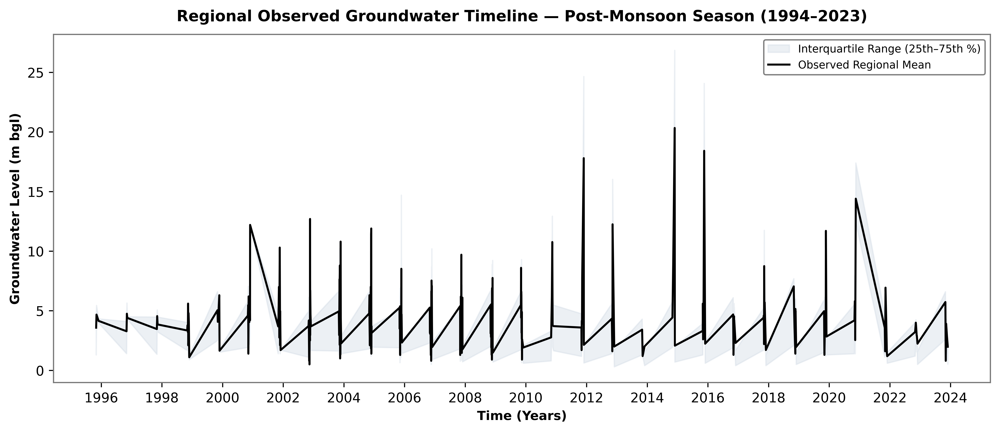

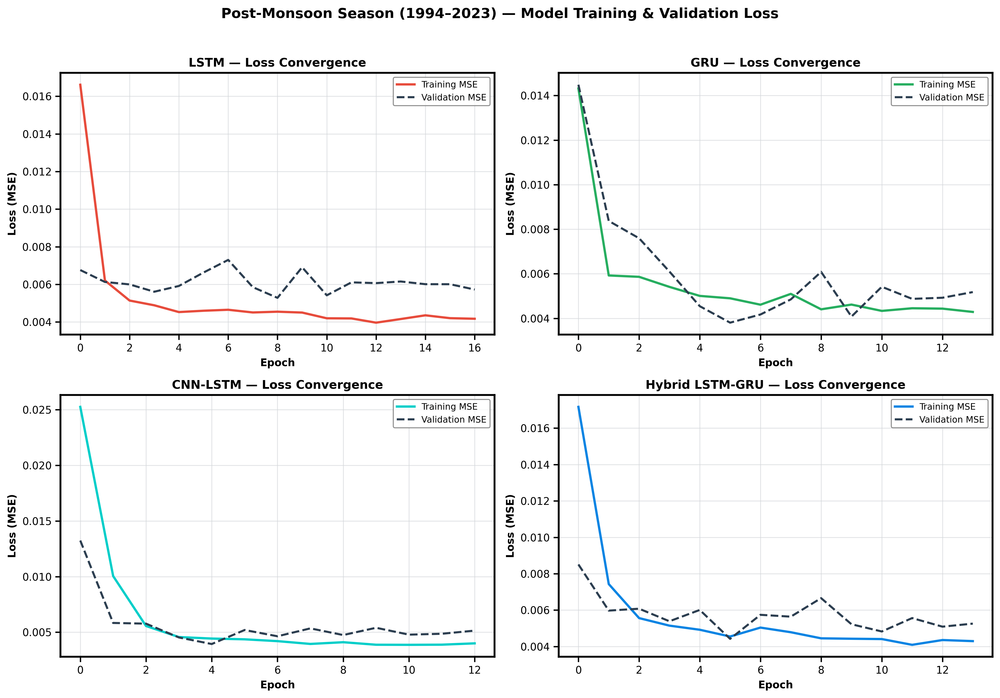

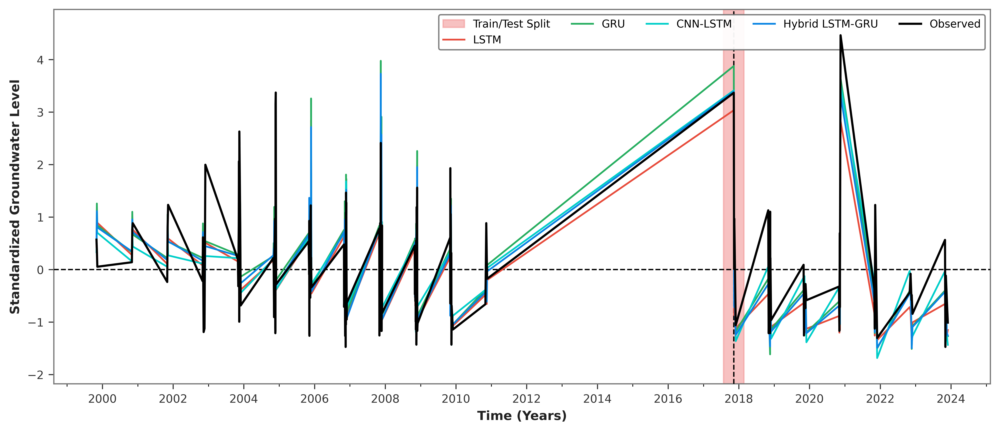

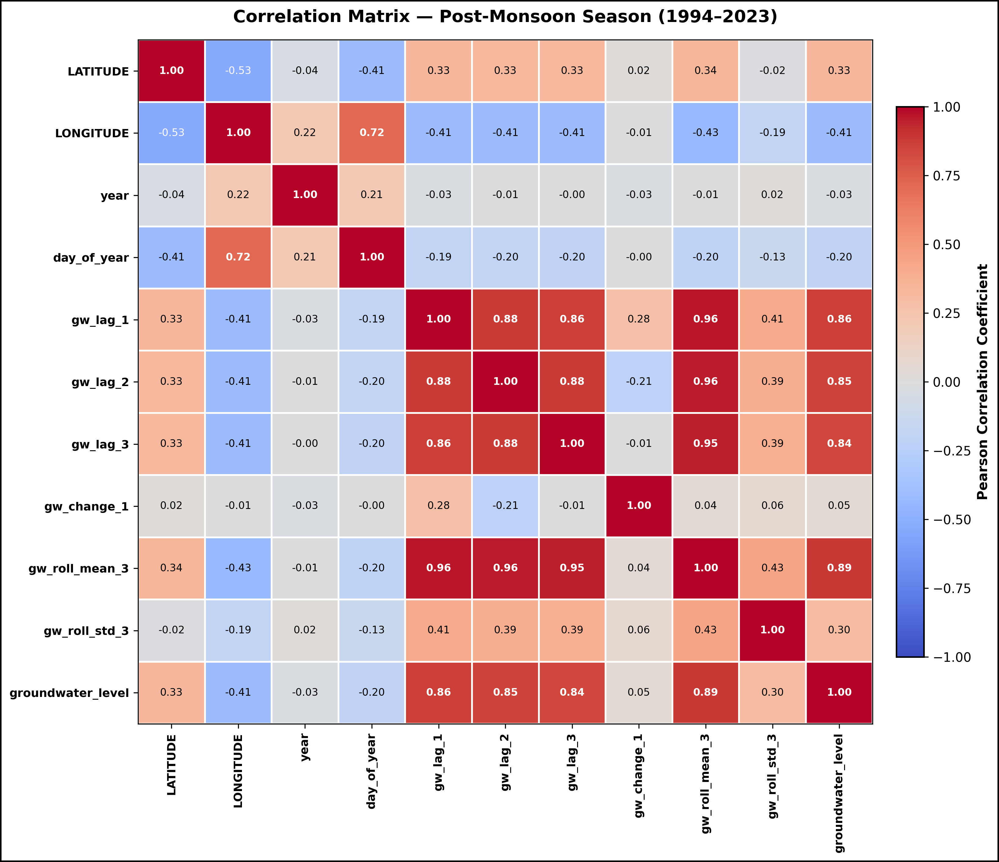

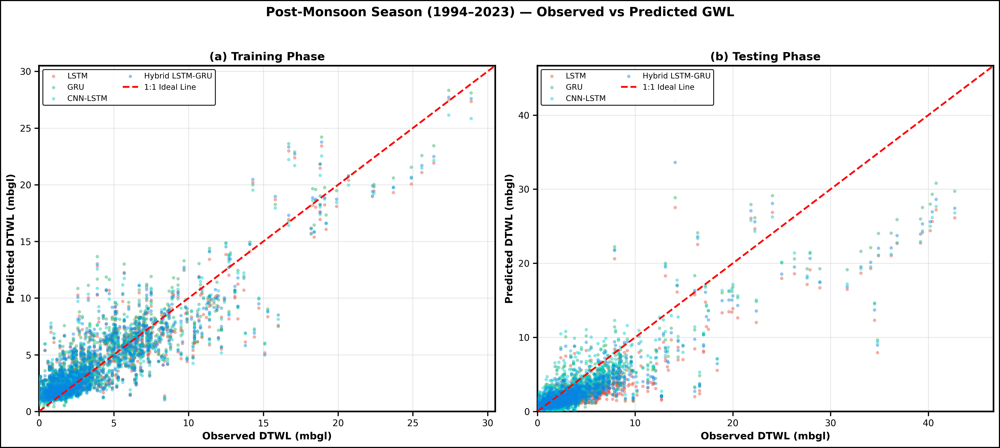

...

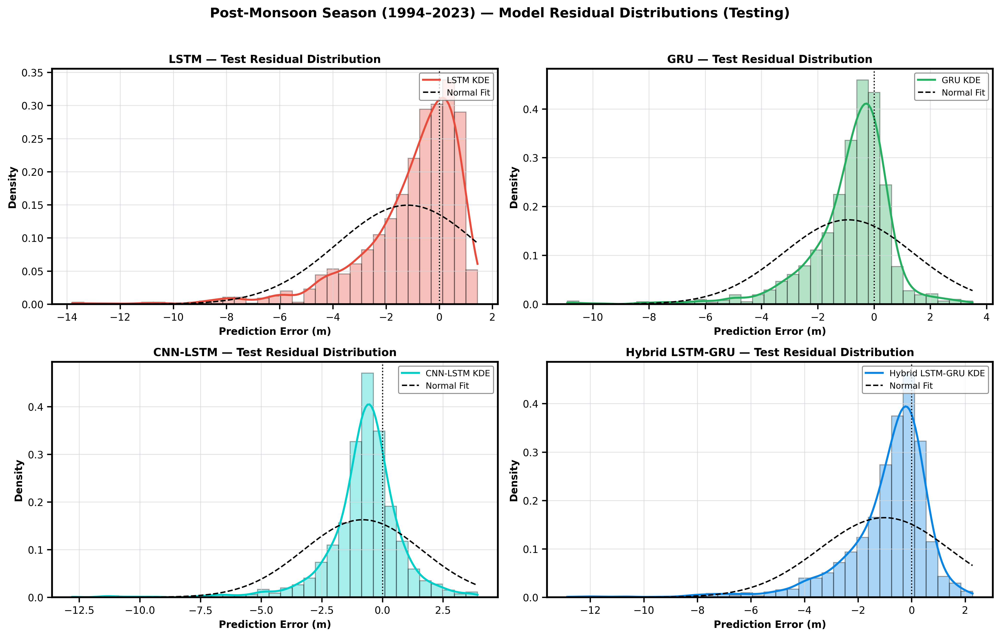

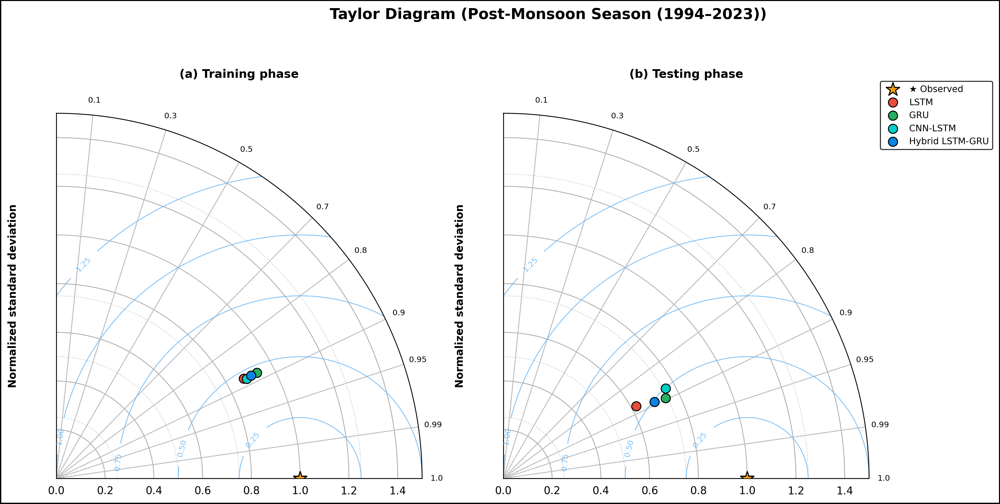

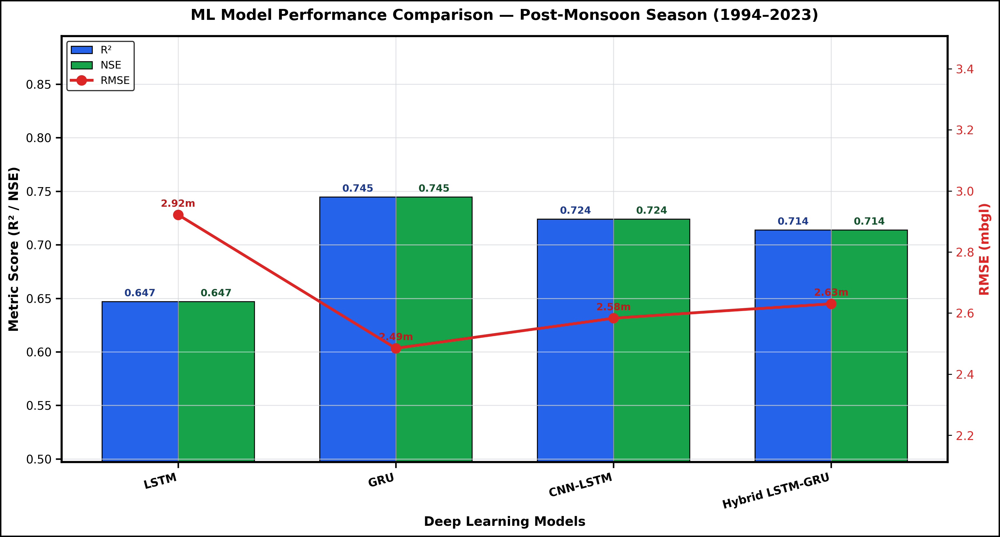

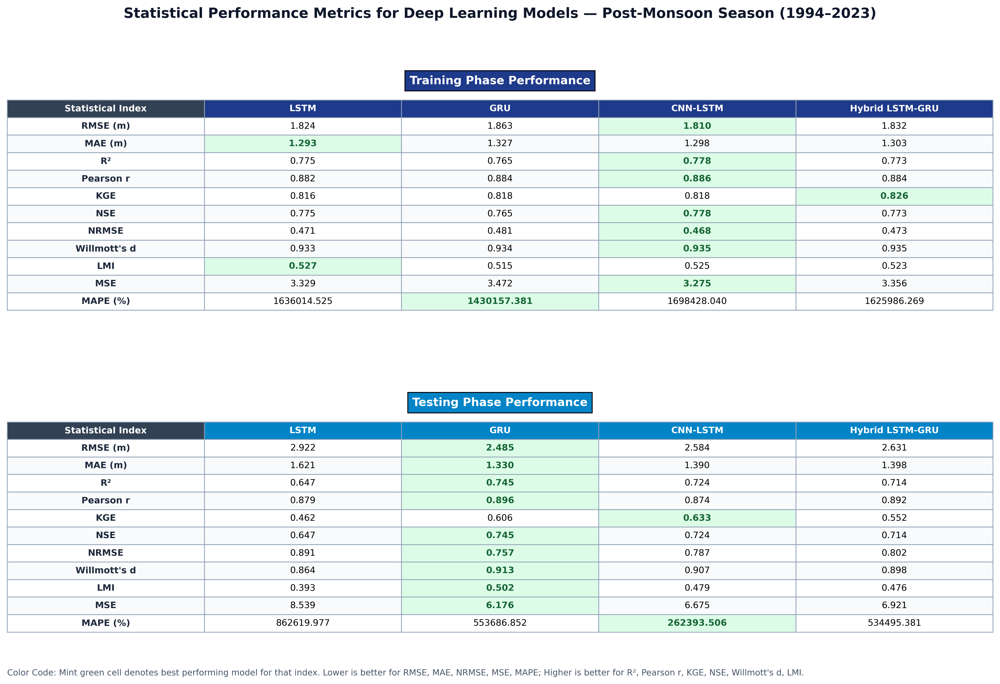

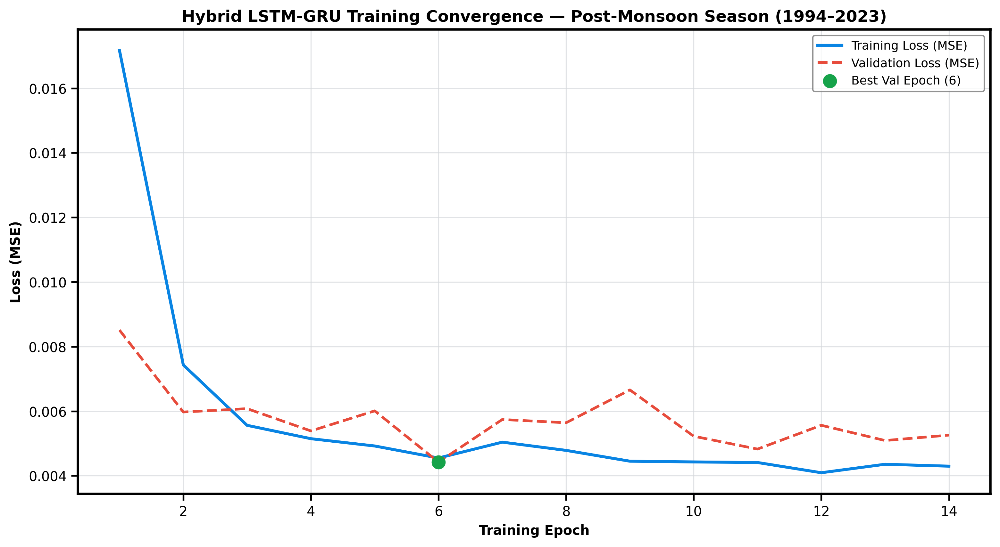


TESTING METRICS
          Model   RMSE    MAE     R2  Pearson_r    KGE    NSE
           LSTM 2.9222 1.6209 0.6471     0.8786 0.4618 0.6471
            GRU 2.4851 1.3300 0.7447     0.8960 0.6065 0.7447
       CNN-LSTM 2.5836 1.3904 0.7241     0.8742 0.6335 0.7241
Hybrid LSTM-GRU 2.6309 1.3981 0.7139     0.8919 0.5520 0.7139

Completed Post-Monsoon Season (1994–2023) in 0.43 minutes.
Outputs: outputs\HIGDSS_DL_4_SEPARATE_DATASETS\post_monsoon_1994_2023


DATASET: Pre-Monsoon Season (2014–2024)
FILE: pre-monsoon_2014-2024.csv
Rows=161,224 | Wells=27,107 | Dates=2014-05-20 -> 2024-05-10
Train: 2014-05-20 -> 2020-05-19 | 89,107 rows
Val:   2020-05-20 -> 2022-03-01 | 16,206 rows
Test:  2022-04-01 -> 2024-05-10 | 55,911 rows
Train     : X=(14189, 4, 13), y=(14189, 1)
Val       : X=(12104, 4, 13), y=(12104, 1)
Test      : X=(44233, 4, 13), y=(44233, 1)

[TRAINING] LSTM — Pre-Monsoon Season (2014–2024)
Epoch 1/40
111/111 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 0.0010 - mae: 0.0193 - val_los

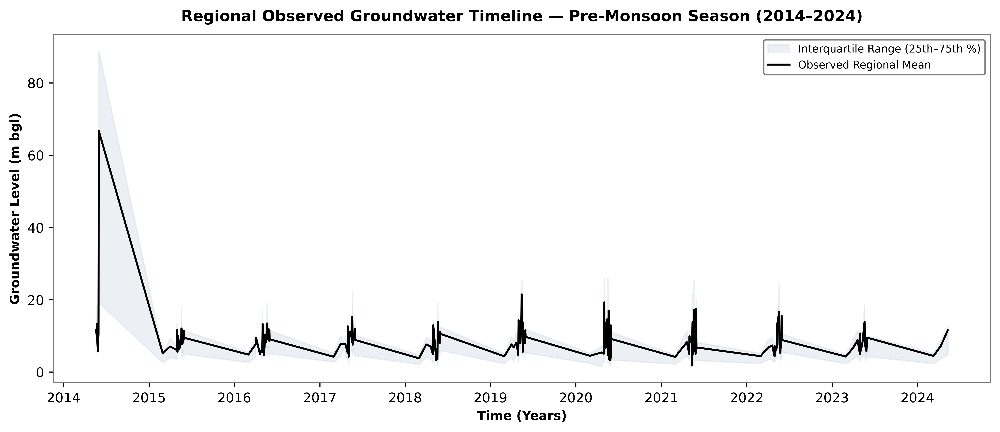

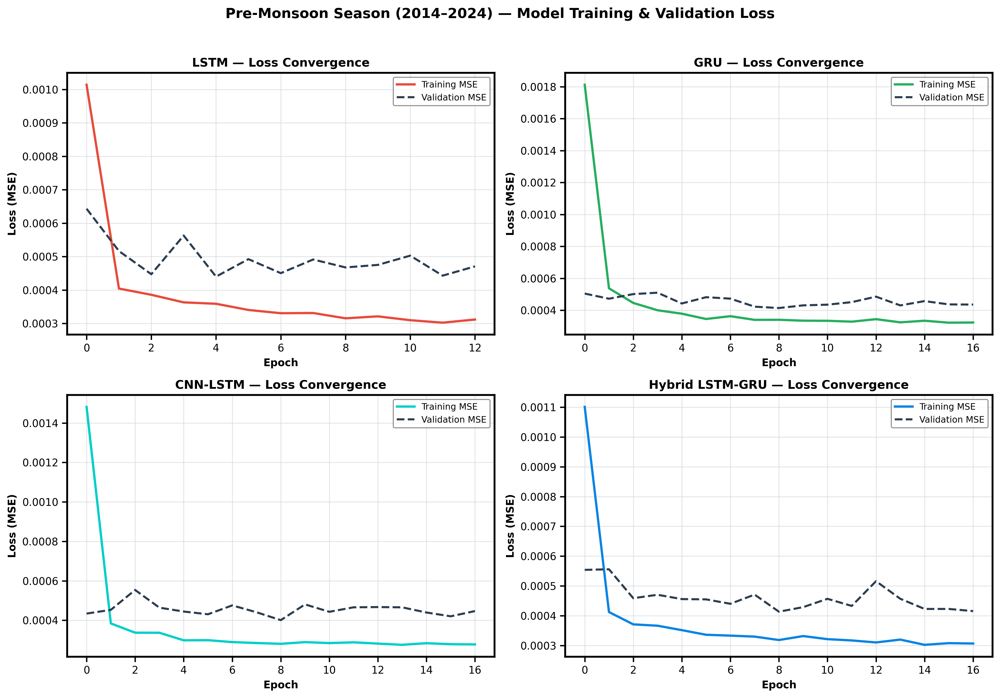

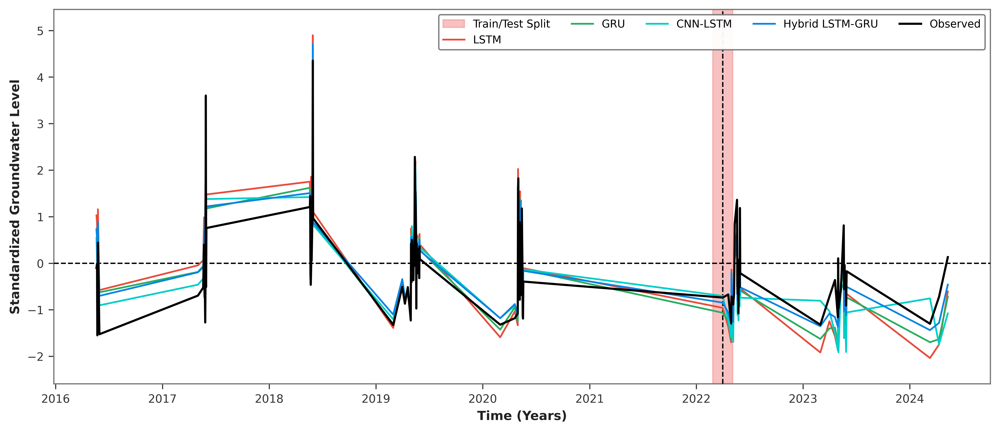

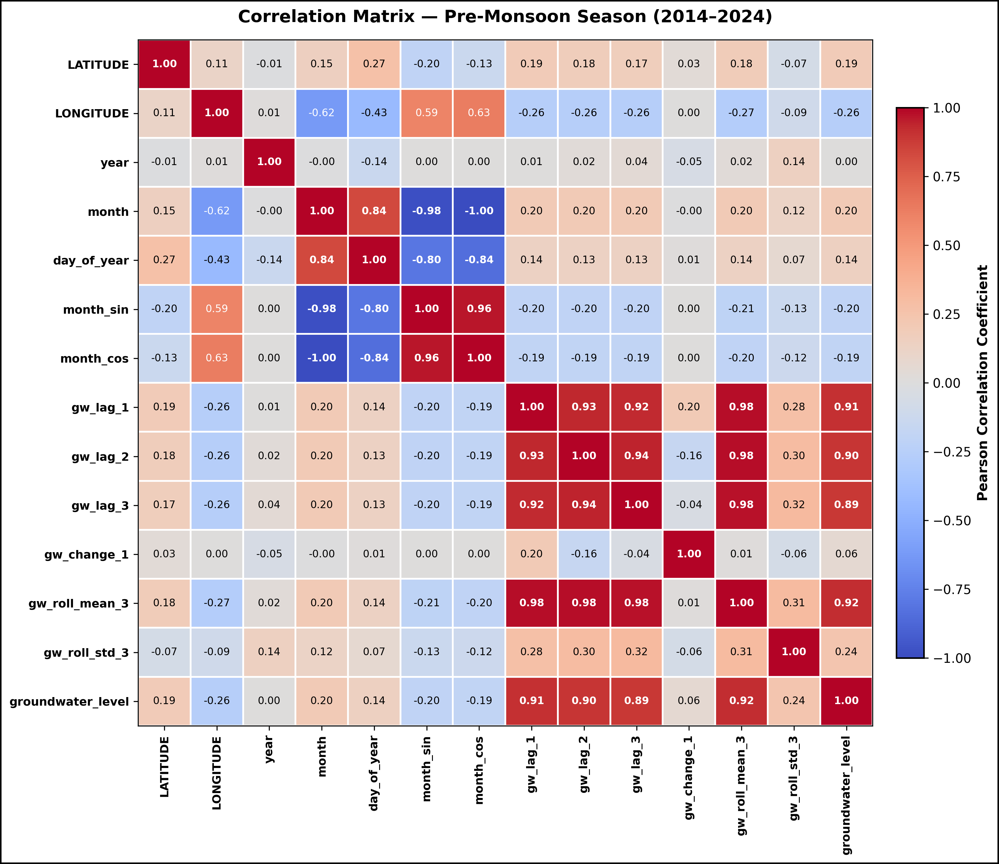

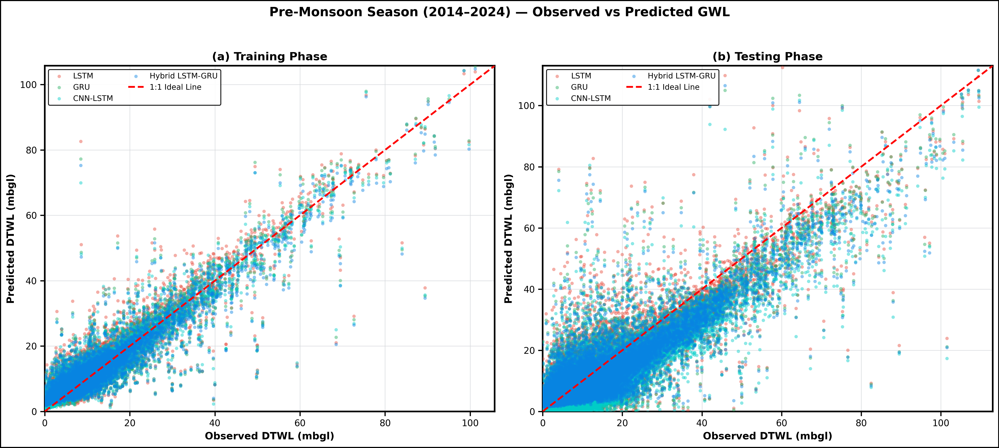

...

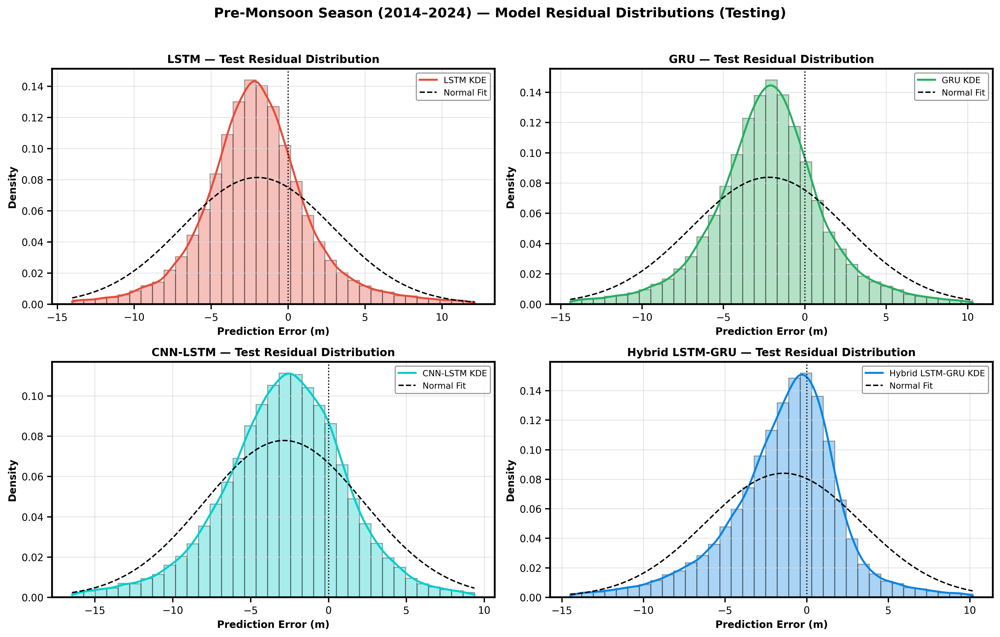

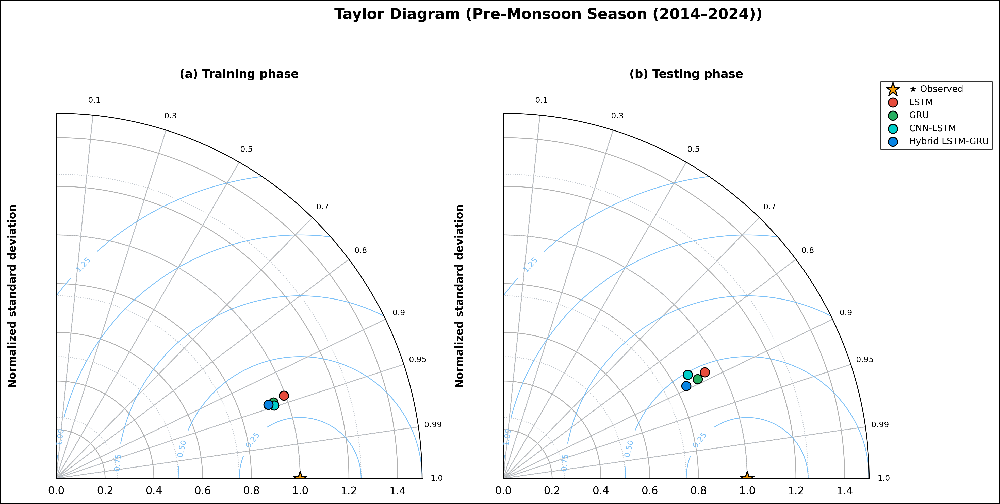

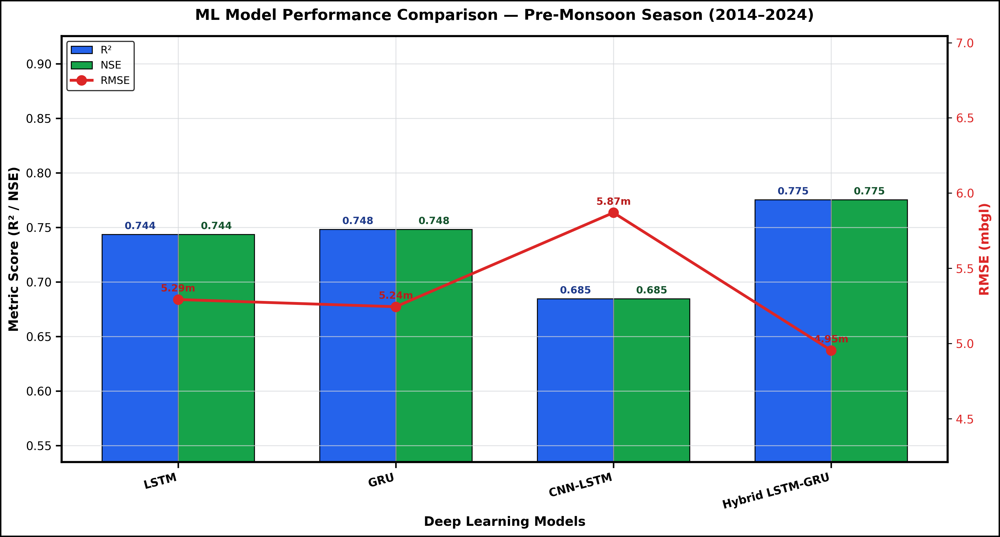

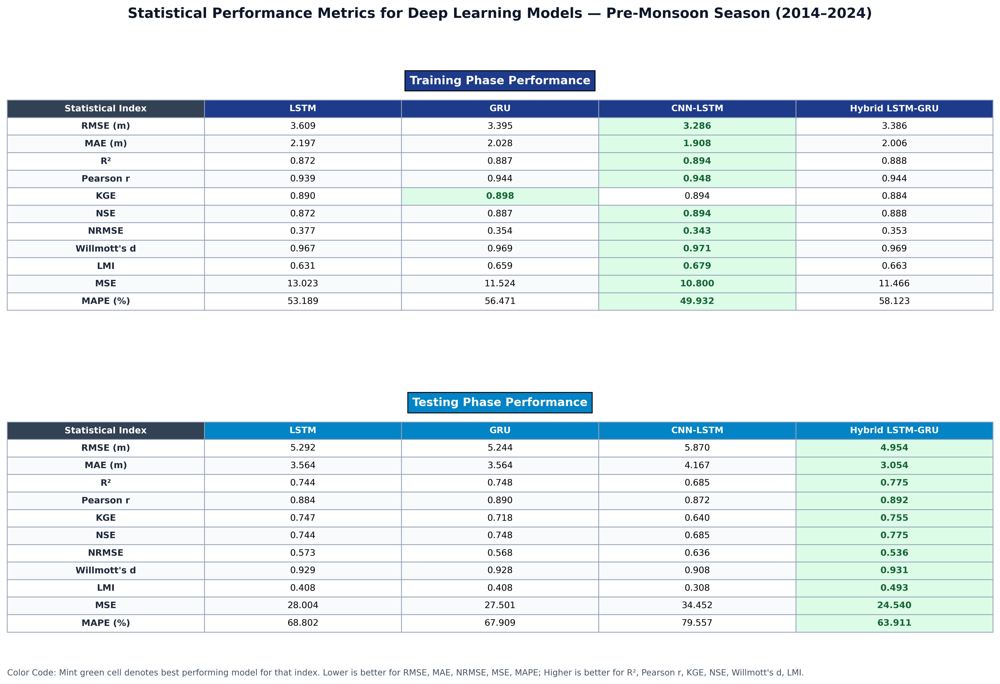

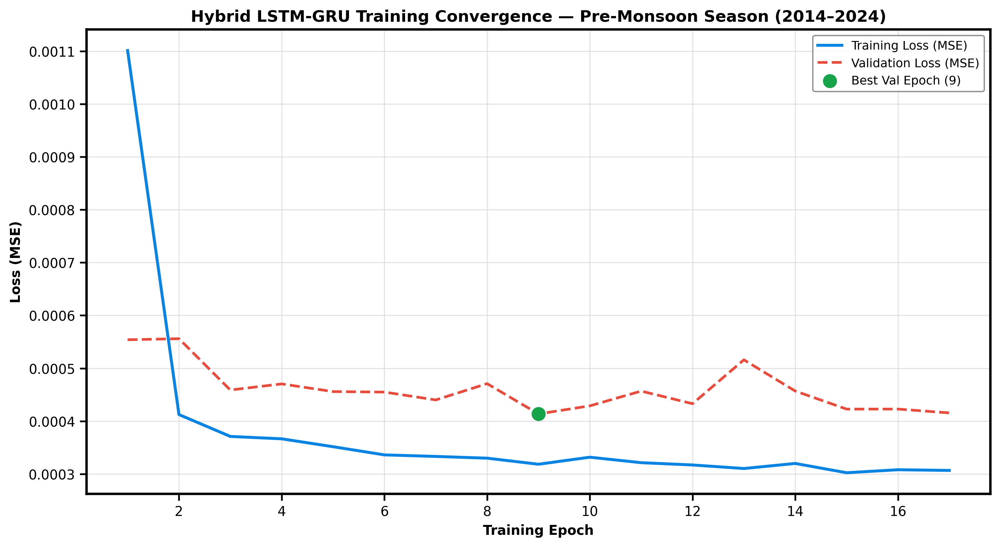


TESTING METRICS
          Model   RMSE    MAE     R2  Pearson_r    KGE    NSE
           LSTM 5.2919 3.5642 0.7437     0.8845 0.7471 0.7437
            GRU 5.2441 3.5638 0.7483     0.8901 0.7182 0.7483
       CNN-LSTM 5.8696 4.1668 0.6847     0.8715 0.6396 0.6847
Hybrid LSTM-GRU 4.9537 3.0535 0.7754     0.8923 0.7546 0.7754

Completed Pre-Monsoon Season (2014–2024) in 1.24 minutes.
Outputs: outputs\HIGDSS_DL_4_SEPARATE_DATASETS\pre_monsoon_2014_2024

DATASET: Pre-Monsoon Season (2004–2013)
FILE: pre-monsoon_2004-2013.csv
Rows=97,179 | Wells=16,041 | Dates=2004-05-24 -> 2013-05-31
Train: 2004-05-24 -> 2011-04-26 | 65,742 rows
Val:   2011-04-27 -> 2012-05-05 | 13,073 rows
Test:  2012-05-06 -> 2013-05-31 | 18,364 rows
Train     : X=(15030, 4, 13), y=(15030, 1)
Val       : X=(10662, 4, 13), y=(10662, 1)
Test      : X=(15305, 4, 13), y=(15305, 1)

[TRAINING] LSTM — Pre-Monsoon Season (2004–2013)
Epoch 1/40
118/118 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.0012 - mae: 0.0208 - val_loss: 6.

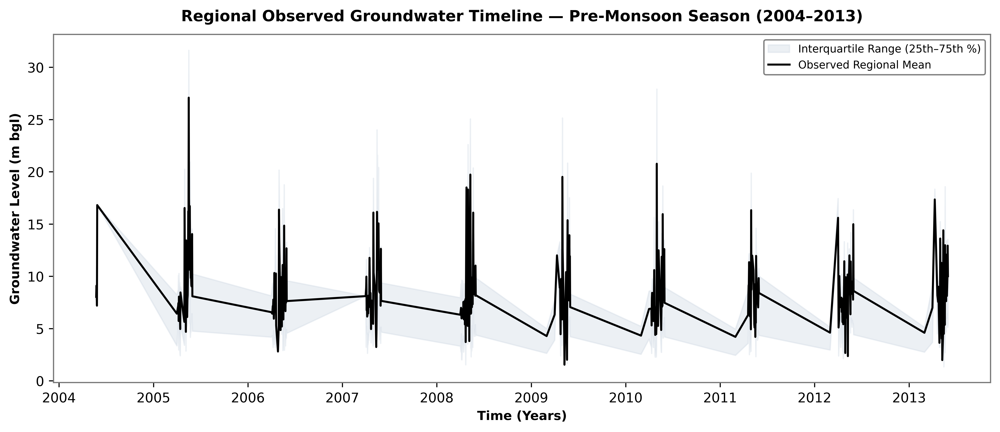

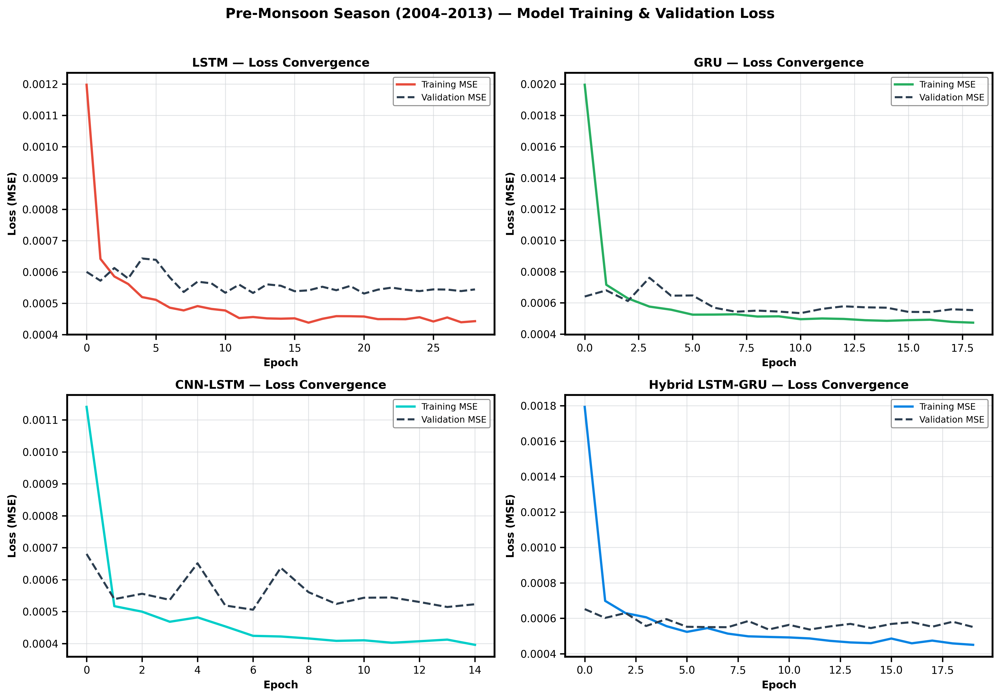

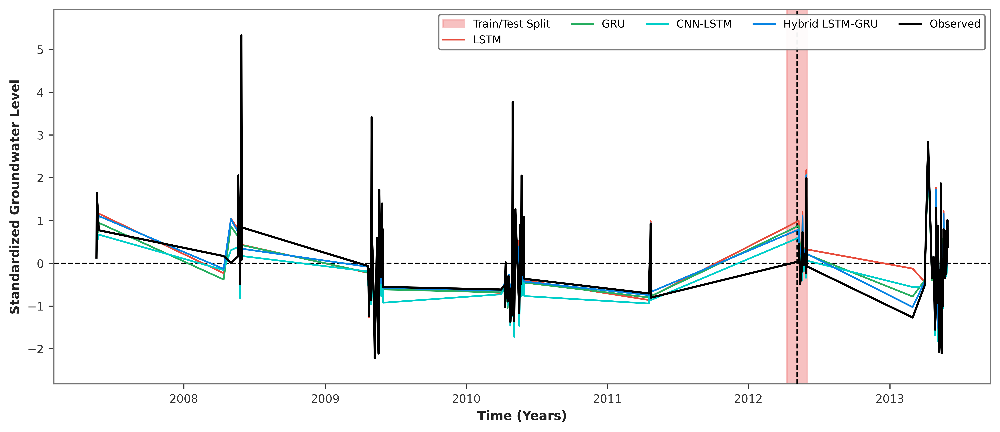

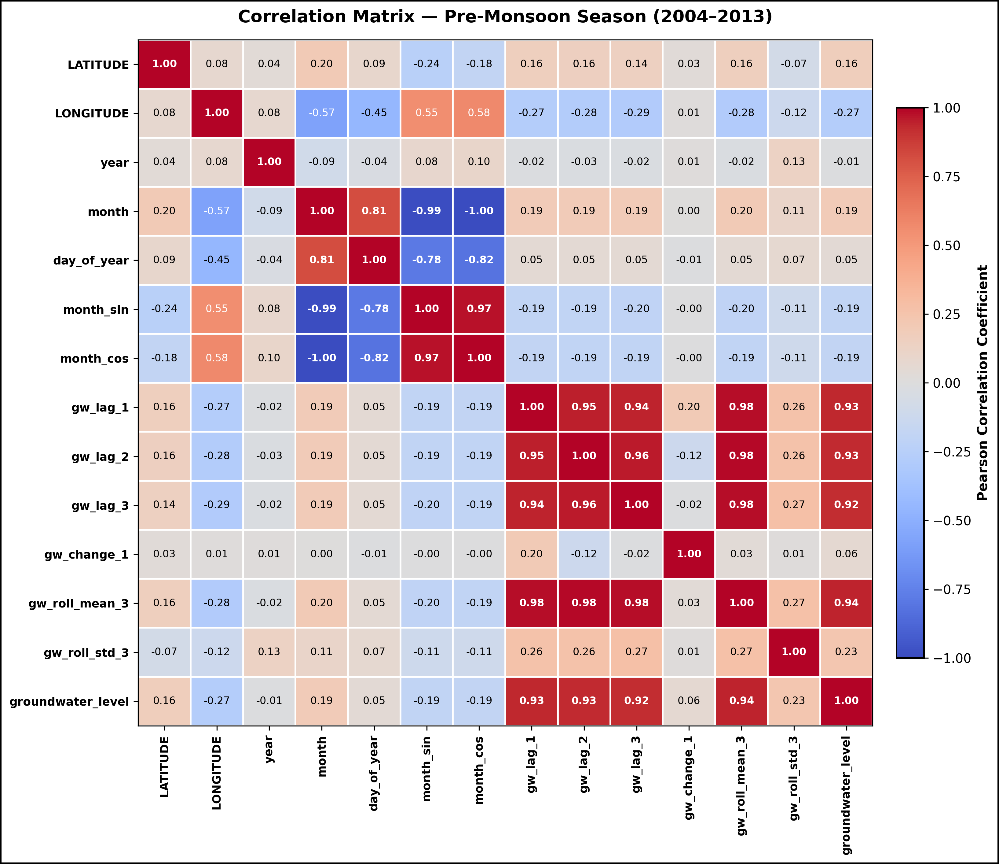

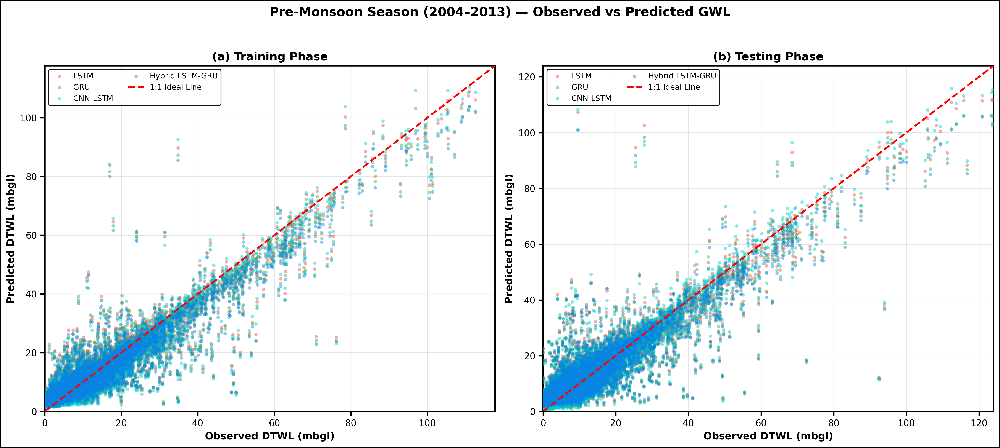

...

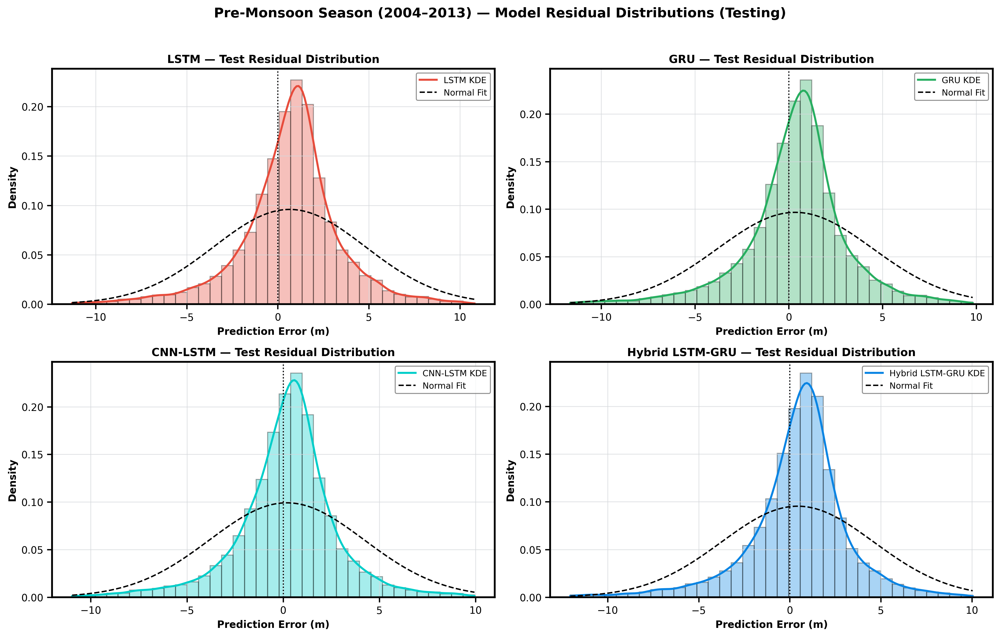

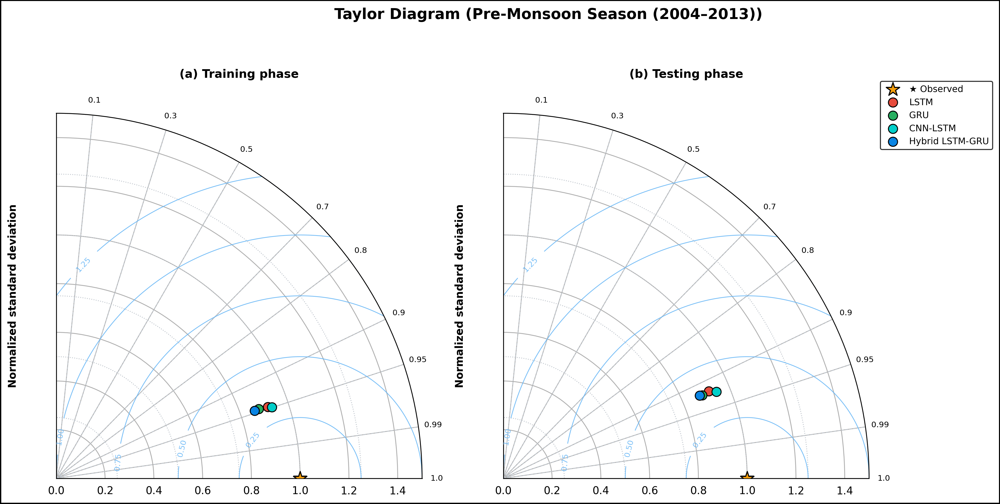

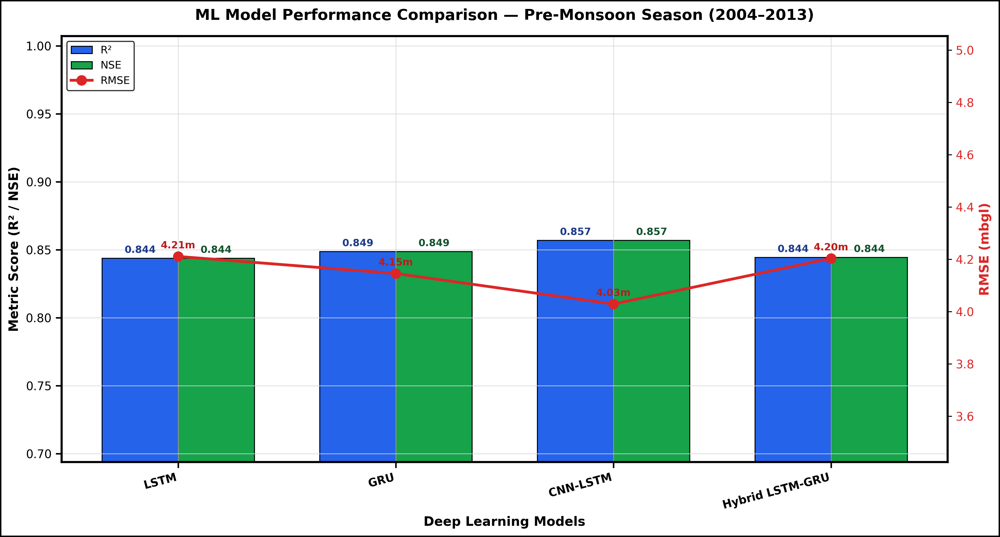

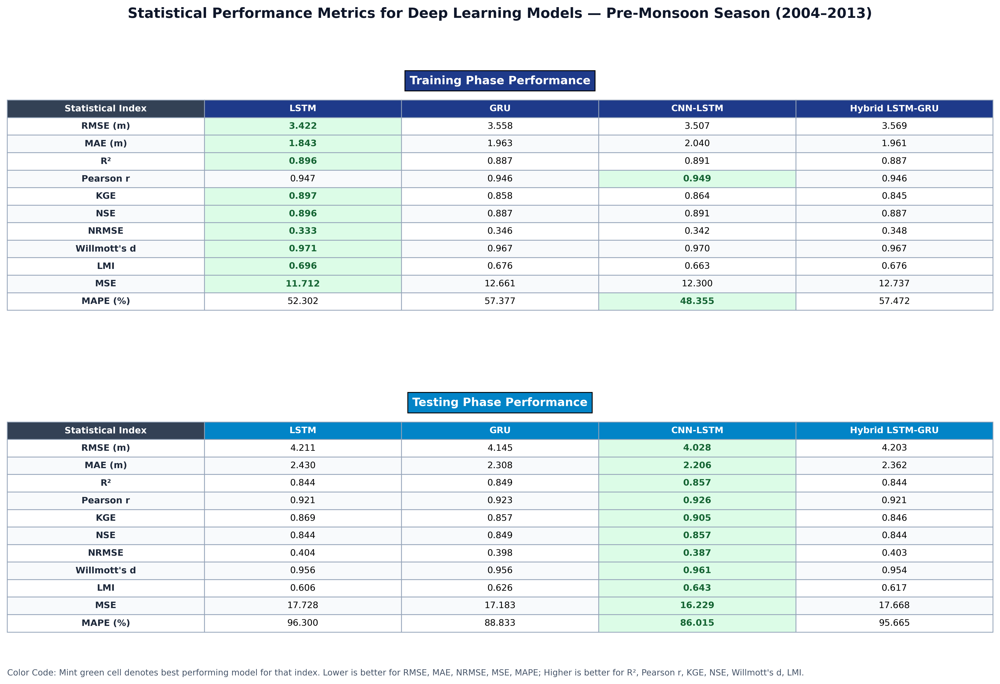

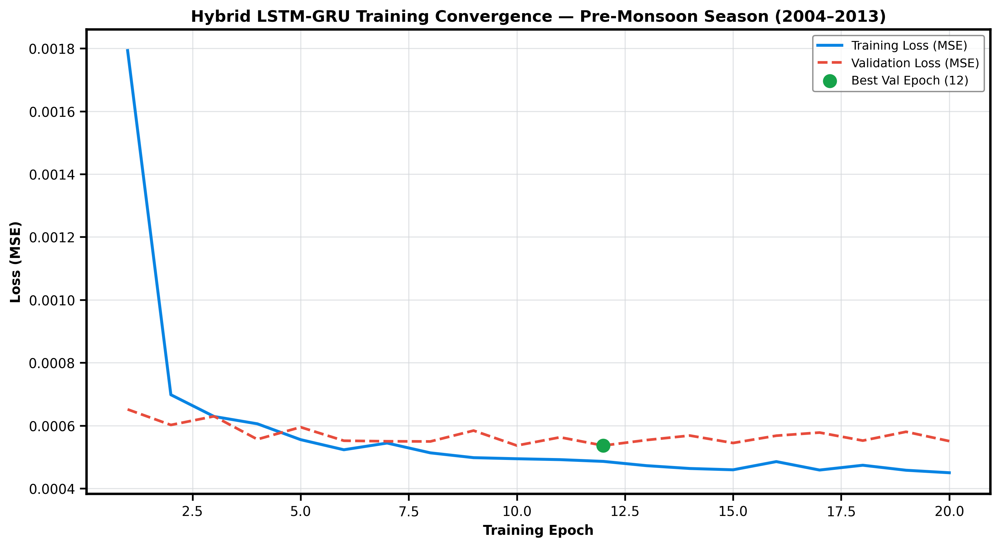


TESTING METRICS
          Model   RMSE    MAE     R2  Pearson_r    KGE    NSE
           LSTM 4.2105 2.4295 0.8438     0.9206 0.8686 0.8438
            GRU 4.1452 2.3075 0.8486     0.9226 0.8567 0.8486
       CNN-LSTM 4.0285 2.2060 0.8570     0.9261 0.9050 0.8570
Hybrid LSTM-GRU 4.2033 2.3617 0.8444     0.9210 0.8459 0.8444

Completed Pre-Monsoon Season (2004–2013) in 1.44 minutes.
Outputs: outputs\HIGDSS_DL_4_SEPARATE_DATASETS\pre_monsoon_2004_2013

DATASET: Pre-Monsoon Season (1994–2003)
FILE: pre-monsoon_1994-2003.csv
Rows=94,956 | Wells=14,854 | Dates=1995-04-01 -> 2003-05-31
Train: 1995-04-01 -> 2001-05-04 | 68,778 rows
Val:   2001-05-05 -> 2002-05-17 | 11,180 rows
Test:  2002-05-18 -> 2003-05-31 | 14,998 rows
Train     : X=(20177, 4, 13), y=(20177, 1)
Val       : X=(8918, 4, 13), y=(8918, 1)
Test      : X=(12532, 4, 13), y=(12532, 1)

[TRAINING] LSTM — Pre-Monsoon Season (1994–2003)
Epoch 1/40
158/158 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 5.9138e-04 - mae: 0.0152 - val_loss: 

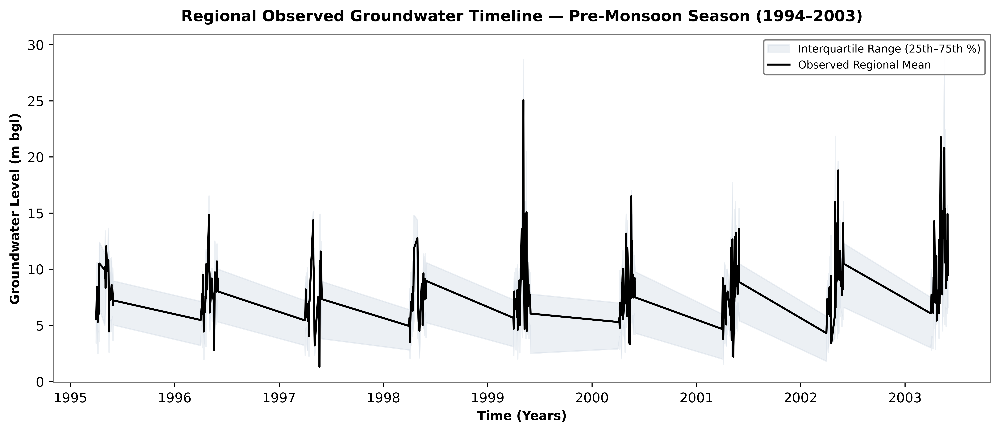

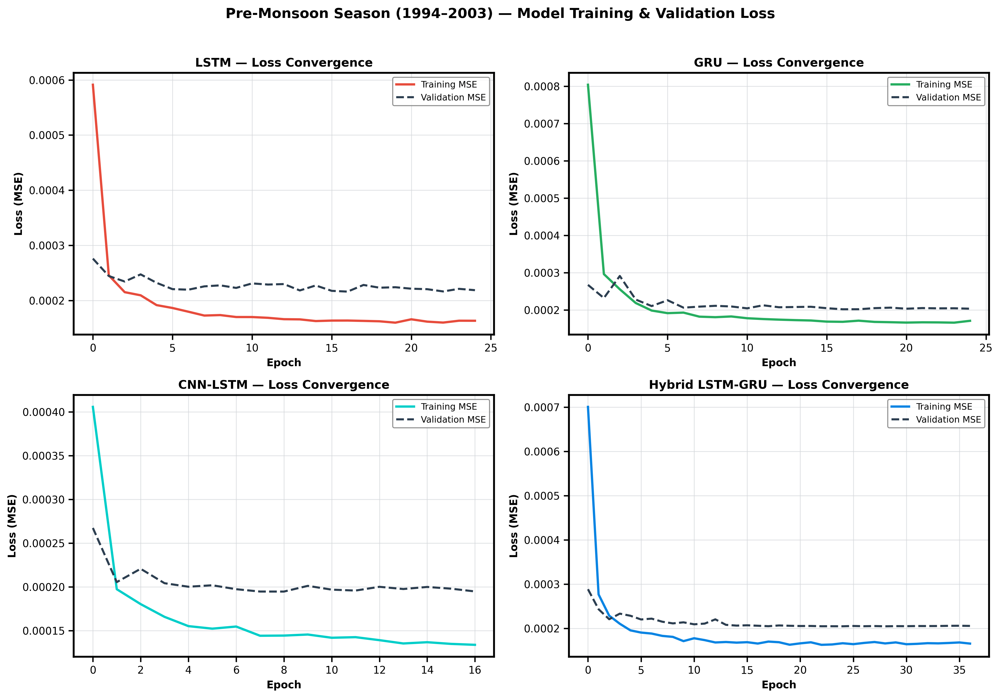

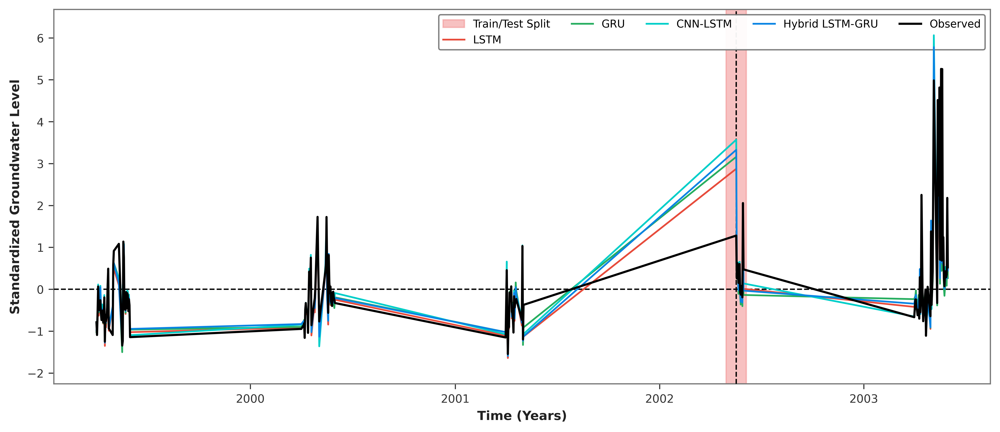

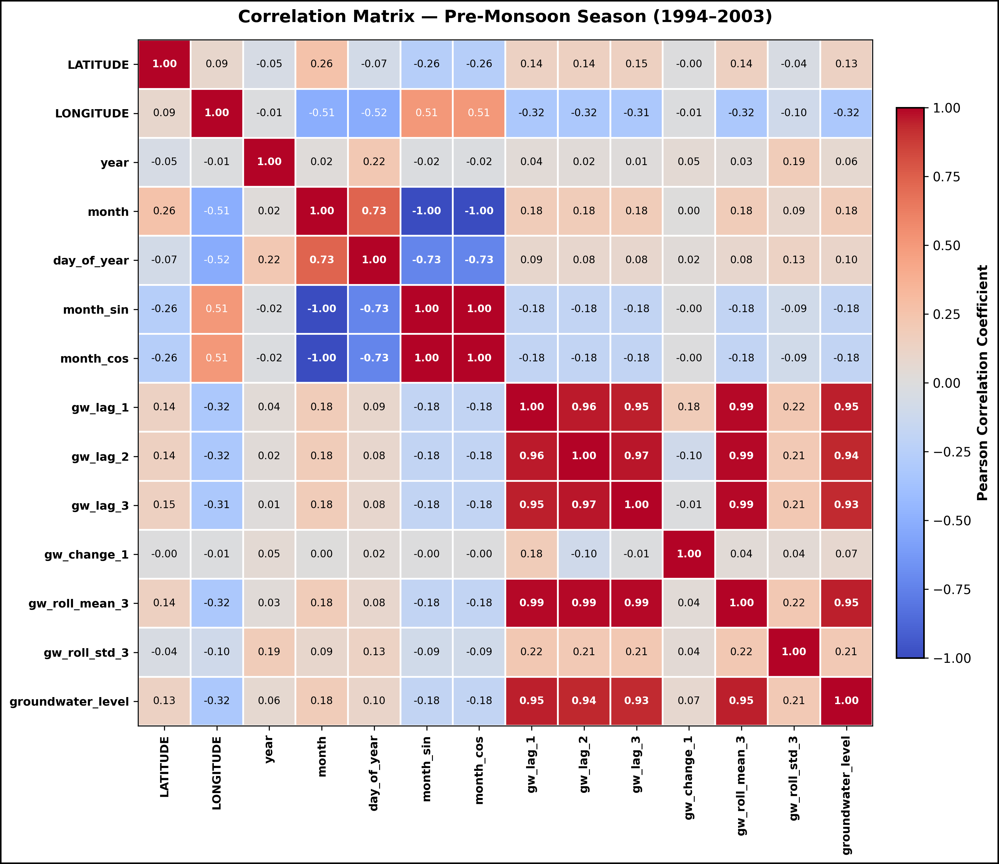

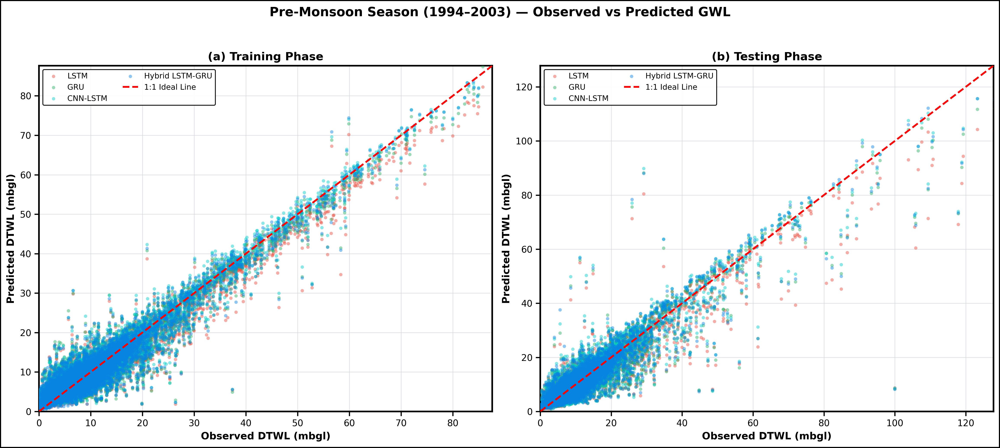

...

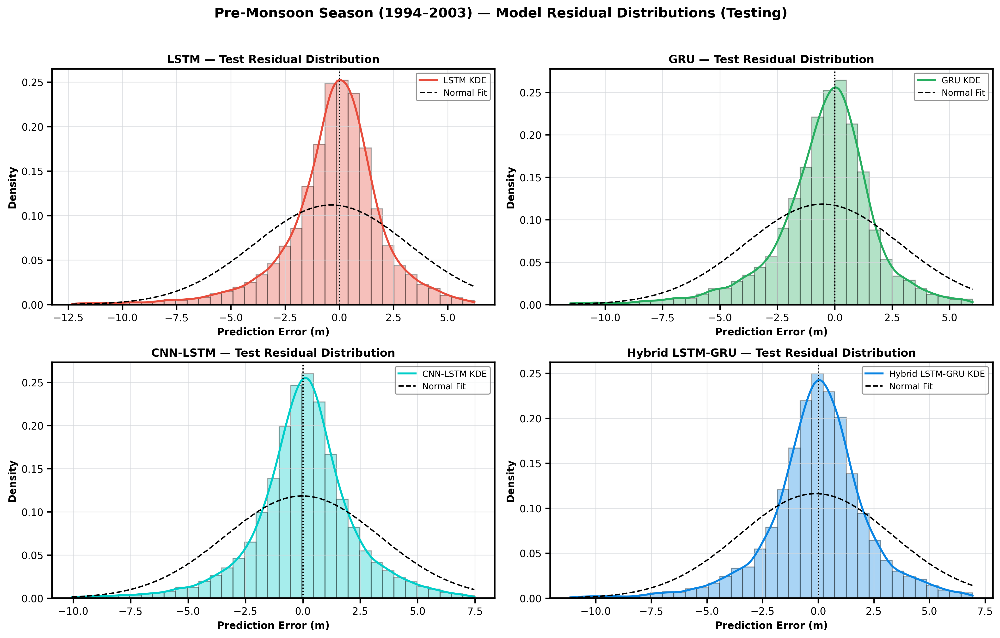

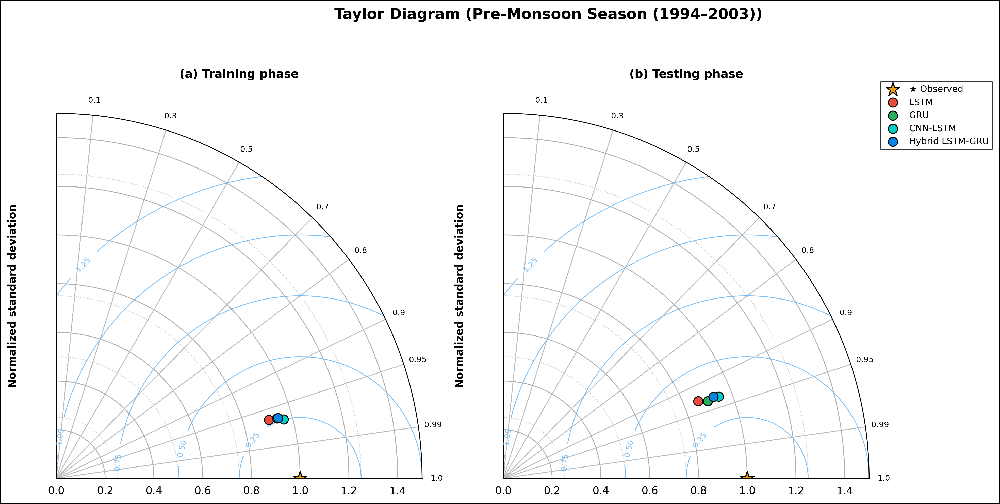

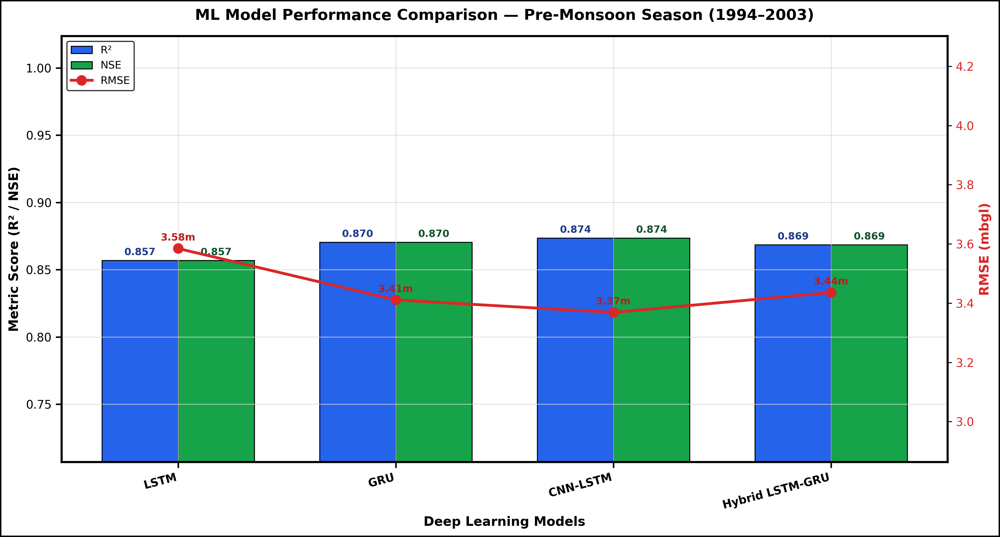

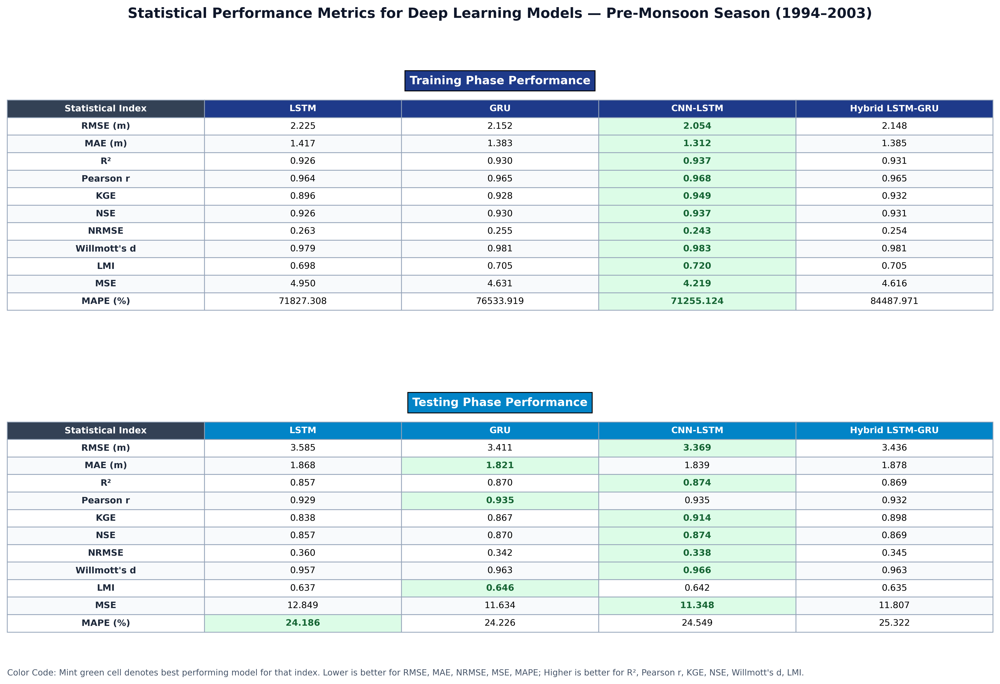

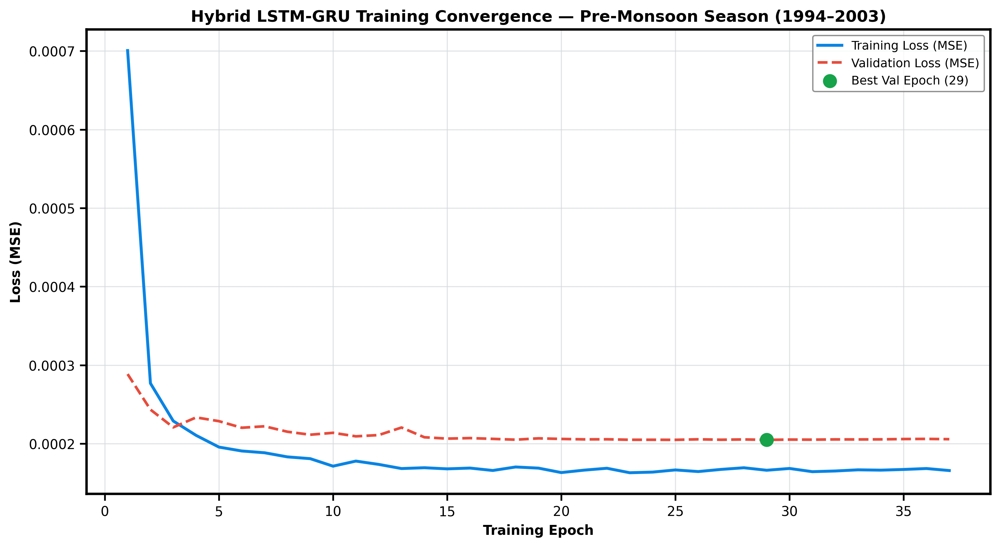


TESTING METRICS
          Model   RMSE    MAE     R2  Pearson_r    KGE    NSE
           LSTM 3.5846 1.8679 0.8569     0.9291 0.8383 0.8569
            GRU 3.4109 1.8208 0.8704     0.9354 0.8670 0.8704
       CNN-LSTM 3.3687 1.8388 0.8736     0.9347 0.9143 0.8736
Hybrid LSTM-GRU 3.4361 1.8783 0.8685     0.9320 0.8979 0.8685

Completed Pre-Monsoon Season (1994–2003) in 2.47 minutes.
Outputs: outputs\HIGDSS_DL_4_SEPARATE_DATASETS\pre_monsoon_1994_2003

ALL FOUR DATASETS COMPLETED
                        Dataset                                             Output_Directory
Post-Monsoon Season (1994–2023) outputs\HIGDSS_DL_4_SEPARATE_DATASETS\post_monsoon_1994_2023
 Pre-Monsoon Season (2014–2024)  outputs\HIGDSS_DL_4_SEPARATE_DATASETS\pre_monsoon_2014_2024
 Pre-Monsoon Season (2004–2013)  outputs\HIGDSS_DL_4_SEPARATE_DATASETS\pre_monsoon_2004_2013
 Pre-Monsoon Season (1994–2003)  outputs\HIGDSS_DL_4_SEPARATE_DATASETS\pre_monsoon_1994_2003


In [10]:
run_summary = []
for dataset_key, filename in DATASET_FILES.items():
    run_summary.append(train_one_dataset(dataset_key, filename))

summary_df = pd.DataFrame(run_summary)
summary_df.to_csv(OUTPUT_ROOT / "Four_Dataset_Run_Summary.csv", index=False)

print("\n" + "=" * 90)
print("ALL FOUR DATASETS COMPLETED")
print("=" * 90)
print(summary_df.to_string(index=False))


In [11]:
print("Output root:", OUTPUT_ROOT.resolve())
for dataset_key in DATASET_FILES:
    d = OUTPUT_ROOT / dataset_key
    print(f"\n{dataset_key}/")
    if d.exists():
        for p in sorted(d.rglob("*")):
            if p.is_file():
                print("  ", p.relative_to(d))


Output root: C:\1 D drive\DL codes for pre and post\outputs\HIGDSS_DL_4_SEPARATE_DATASETS

post_monsoon_1994_2023/
   dataset_profile.json
   figures\00_Observed_Regional_Timeline.png
   figures\00_Observed_Regional_Timeline_interactive.html
   figures\01_Training_Validation_Loss.png
   figures\01_Training_Validation_Loss_interactive.html
   figures\02_Time_Series_Observed_vs_Predicted.png
   figures\02_Time_Series_Observed_vs_Predicted_interactive.html
   figures\03_Correlation_Matrix.png
   figures\03_Correlation_Matrix_interactive.html
   figures\04_Scatter_Observed_vs_Predicted.png
   figures\04_Scatter_Observed_vs_Predicted_interactive.html
   figures\05_Test_Residuals_vs_Time.png
   figures\05_Test_Residuals_vs_Time_interactive.html
   figures\06_Test_Residual_Distributions.png
   figures\06_Test_Residual_Distributions_interactive.html
   figures\07_Taylor_Diagram_Training_Testing.png
   figures\07_Taylor_Diagram_Training_Testing_interactive.html
   figures\08_Model_Performance_C


--- Loading Results & Interactive Figures for: Pre-Monsoon Season (2014–2024) ---


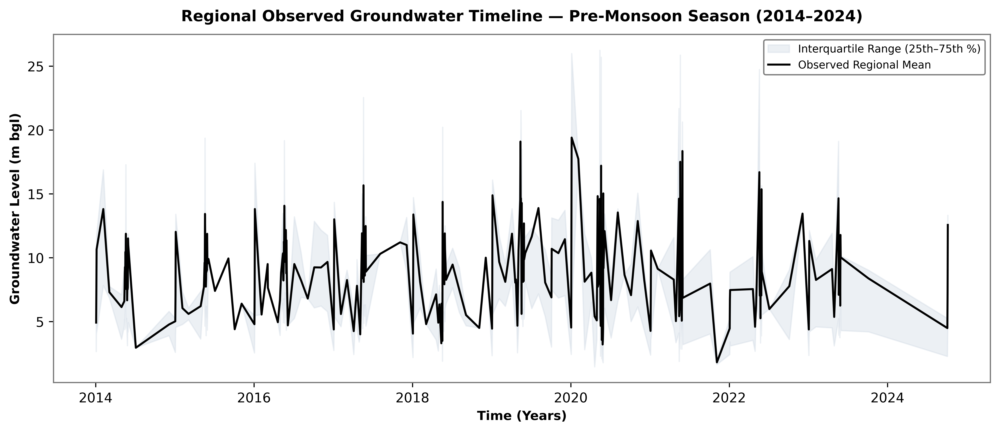

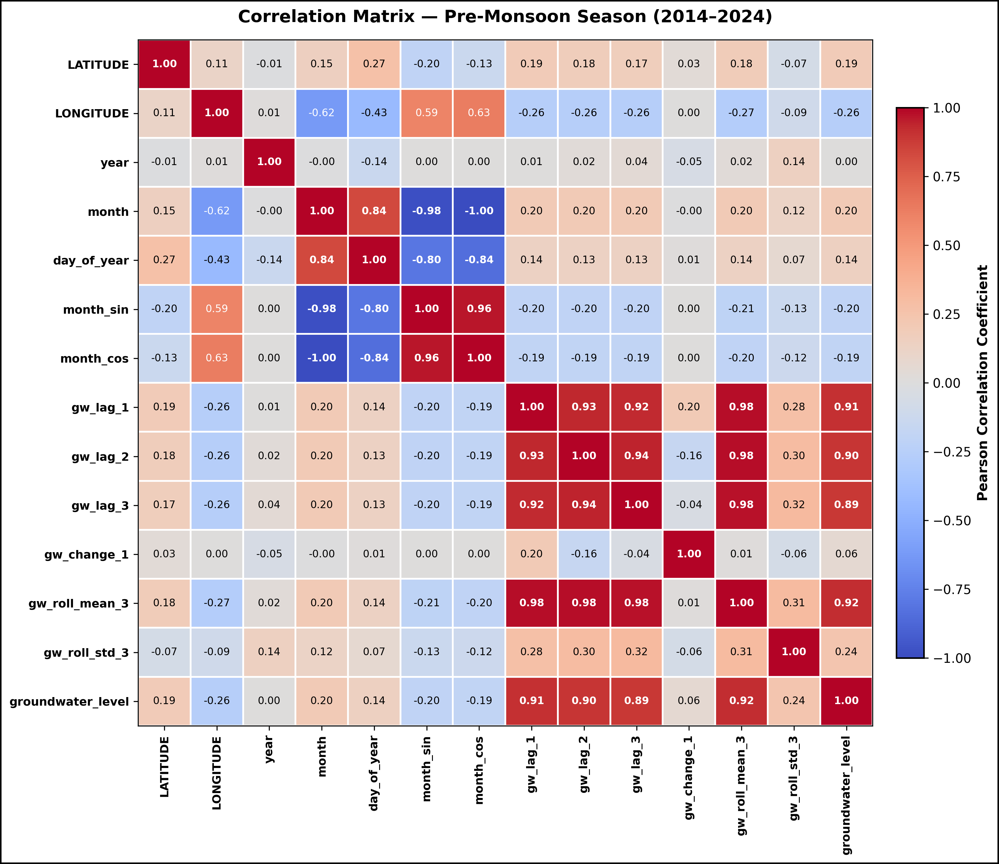

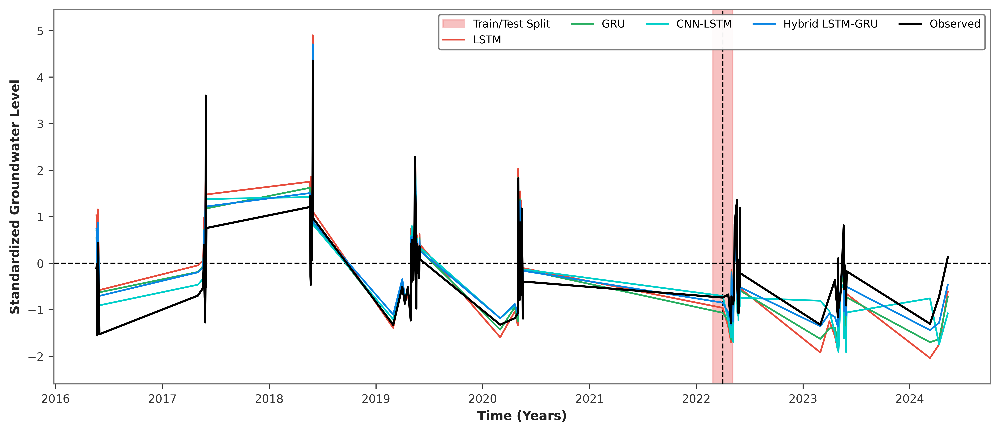

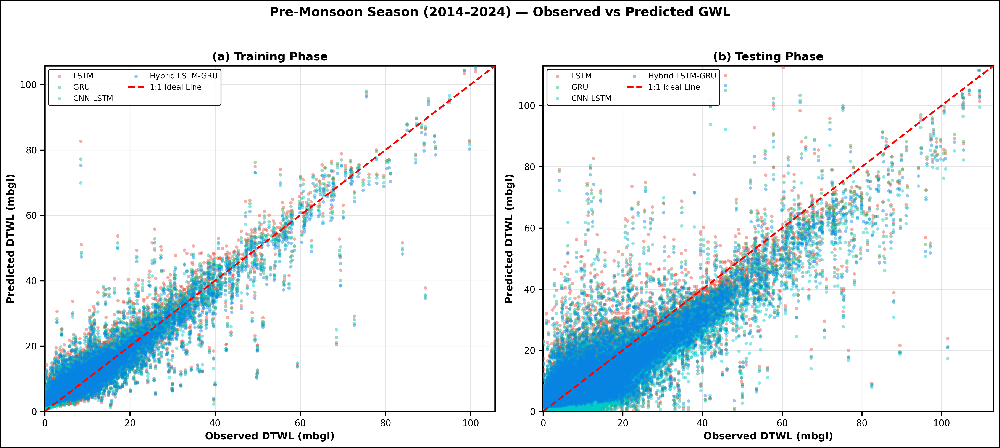

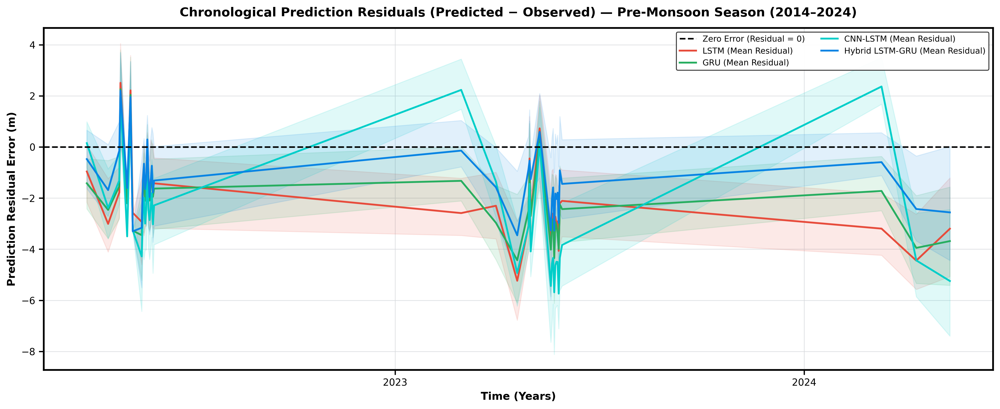

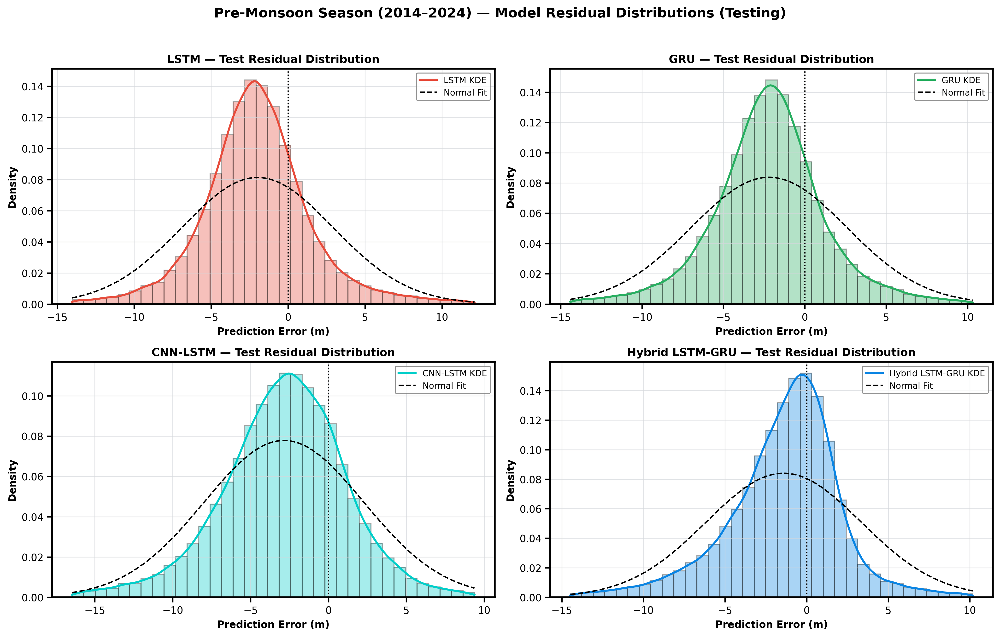

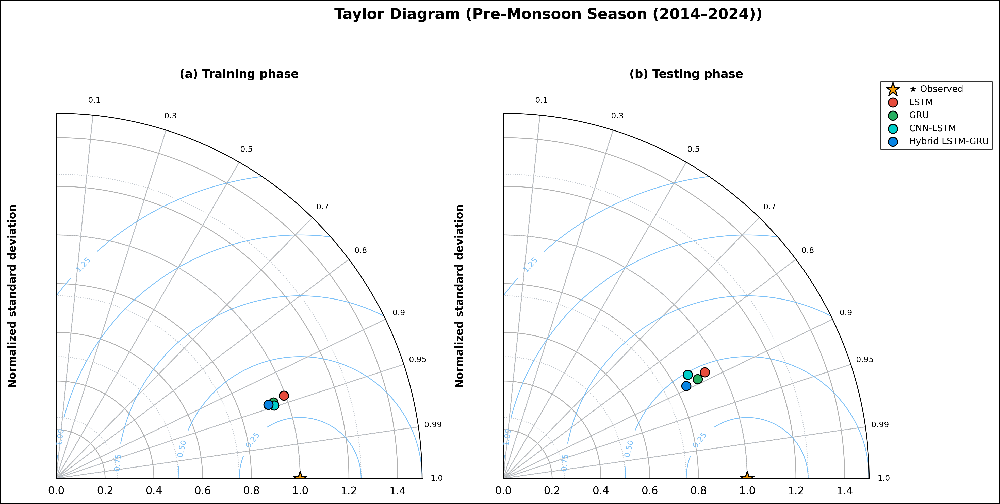

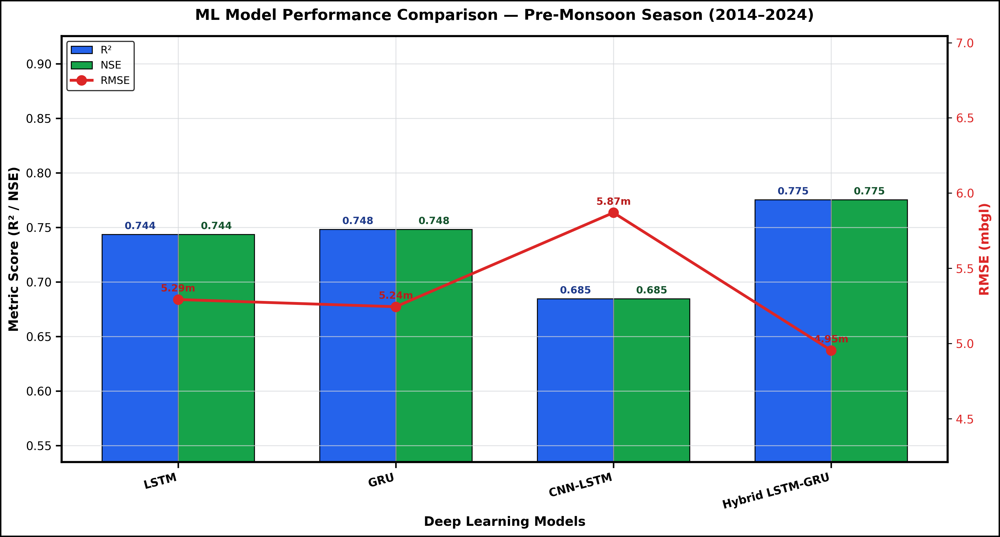

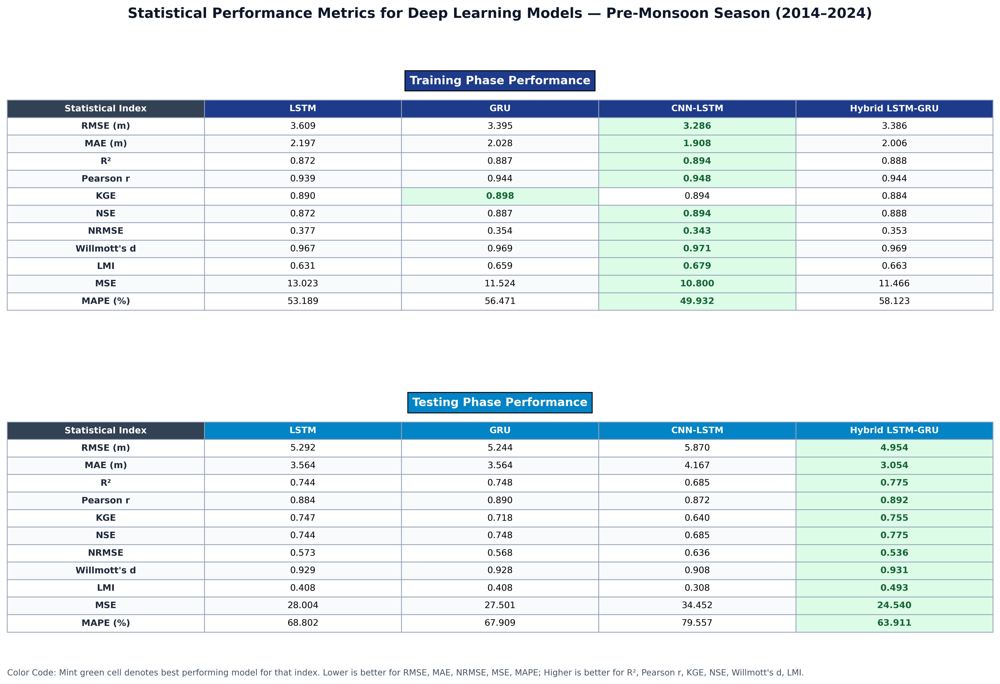

Interactive figures displayed and saved to: outputs\HIGDSS_DL_4_SEPARATE_DATASETS\pre_monsoon_2014_2024\figures


In [12]:
# ==============================================================================
# ON-DEMAND INTERACTIVE VISUALIZER & REPORT GENERATOR
# Instantly view interactive figures & export publication PNGs from saved results
# ==============================================================================
from IPython.display import display, HTML

def visualize_saved_dataset(dataset_key):
    dataset_titles = {
        "post_monsoon_1994_2023": "Post-Monsoon Season (1994–2023)",
        "pre_monsoon_2014_2024": "Pre-Monsoon Season (2014–2024)",
        "pre_monsoon_2004_2013": "Pre-Monsoon Season (2004–2013)",
        "pre_monsoon_1994_2003": "Pre-Monsoon Season (1994–2003)",
    }
    dataset_title = dataset_titles.get(dataset_key, dataset_key)
    dataset_dir = OUTPUT_ROOT / dataset_key
    fig_dir = dataset_dir / "figures"
    table_dir = dataset_dir / "tables"
    fig_dir.mkdir(parents=True, exist_ok=True)

    print(f"\n=======================================================")
    print(f"--- Loading Results & Interactive Figures for: {dataset_title} ---")
    print(f"=======================================================")
    
    # 0. Observed Regional Timeline
    csv_file = DATASET_FILES.get(dataset_key)
    if csv_file and Path(csv_file).exists():
        raw = pd.read_csv(csv_file, low_memory=False)
        plot_observed_timeline(raw, fig_dir / "00_Observed_Regional_Timeline.png", dataset_title)

    # 1. Correlation Matrix
    if (table_dir / "03_Correlation_Matrix.csv").exists():
        corr = pd.read_csv(table_dir / "03_Correlation_Matrix.csv", index_col=0)
        plot_correlation_matrix(corr, fig_dir / "03_Correlation_Matrix.png", dataset_title)
        
    # 2. Predictions & Performance
    tr_path = table_dir / "Training_Predictions_All_Models.csv"
    te_path = table_dir / "Testing_Predictions_All_Models.csv"
    if tr_path.exists() and te_path.exists():
        train_preds = pd.read_csv(tr_path)
        test_preds = pd.read_csv(te_path)
        train_preds["Date"] = pd.to_datetime(train_preds["Date"])
        test_preds["Date"] = pd.to_datetime(test_preds["Date"])
        combined_preds = pd.concat([train_preds, test_preds], ignore_index=True)
        split_date = test_preds["Date"].min()

        # Time Series
        plot_time_series(combined_preds, split_date, fig_dir / "02_Time_Series_Observed_vs_Predicted.png", dataset_title)
        
        # Parity Scatter
        models = [m for m in MODEL_COLORS if m in train_preds.columns]
        ptrain = {m: train_preds[m].values for m in models}
        ptest = {m: test_preds[m].values for m in models}
        plot_parity(ptrain, train_preds["Observed"].values, ptest, test_preds["Observed"].values, fig_dir / "04_Scatter_Observed_vs_Predicted.png", dataset_title)
        
        # Residuals
        plot_residuals(test_preds, fig_dir / "05_Test_Residuals_vs_Time.png", dataset_title)
        plot_error_distributions(test_preds, fig_dir / "06_Test_Residual_Distributions.png", dataset_title)

        if (table_dir / "Taylor_Statistics_Training.csv").exists():
            taylor_train = pd.read_csv(table_dir / "Taylor_Statistics_Training.csv")
            taylor_test = pd.read_csv(table_dir / "Taylor_Statistics_Testing.csv")
            plot_taylor({"Training": taylor_train, "Testing": taylor_test}, fig_dir / "07_Taylor_Diagram_Training_Testing.png", dataset_title)

        if (table_dir / "Training_Statistical_Metrics.csv").exists():
            train_metrics = pd.read_csv(table_dir / "Training_Statistical_Metrics.csv")
            test_metrics = pd.read_csv(table_dir / "Testing_Statistical_Metrics.csv")
            plot_performance(train_metrics, test_metrics, fig_dir / "08_Model_Performance_Comparison.png", dataset_title)
            plot_statistical_tables(train_metrics, test_metrics, fig_dir / "09_Statistical_Metrics_Training_Testing.png", dataset_title)
    else:
        # Display baseline observed time series if model predictions not yet trained
        csv_file = DATASET_FILES.get(dataset_key)
        if csv_file and Path(csv_file).exists():
            raw = pd.read_csv(csv_file, low_memory=False)
            date_col = "Date" if "Date" in raw.columns else "date"
            gw_col = "DTWL" if "DTWL" in raw.columns else ("WL_in_mbgl" if "WL_in_mbgl" in raw.columns else "groundwater_level")
            raw["Date"] = pd.to_datetime(raw[date_col], errors="coerce")
            raw = raw.dropna(subset=["Date", gw_col]).rename(columns={gw_col: "Observed"})
            daily_raw = raw.groupby("Date")["Observed"].mean().reset_index()
            split_d = daily_raw["Date"].iloc[int(len(daily_raw)*0.7)]
            plot_time_series(daily_raw, split_d, fig_dir / "02_Time_Series_Observed_vs_Predicted.png", dataset_title)

    print(f"Interactive figures displayed and saved to: {fig_dir}")

# Display interactive figures for Pre-Monsoon 2014-2024 and Post-Monsoon
visualize_saved_dataset("pre_monsoon_2014_2024")
